# Experiment 2 — Email Spam/Ham Classification using Naïve Bayes and KNN

### Aim
To build and compare spam classifiers using Naïve Bayes (Gaussian, Multinomial, Bernoulli) and K-Nearest Neighbours (KNN), tune the KNN hyperparameters using GridSearchCV and RandomizedSearchCV, compare KDTree vs BallTree, and evaluate all models using standard classification metrics.

### Objectives
- Build spam classifiers using Naïve Bayes and KNN.
- Compare Gaussian, Multinomial and Bernoulli Naïve Bayes.
- Study the effect of varying k.
- Compare KDTree and BallTree.
- Optimize KNN using GridSearchCV and RandomizedSearchCV.
- Evaluate computational complexity and execution time.
- Evaluate using K-Fold Cross Validation.



## Step 1 — Setup: Import Libraries


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import time

import warnings
warnings.filterwarnings("ignore")

plt.style.use("default")
sns.set_style("whitegrid")
# Global Plot Formatting (rules.md compliance)
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['Times New Roman']
plt.rcParams['font.size'] = 15
plt.rcParams['axes.labelsize'] = 15
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['axes.titlesize'] = 15
plt.rcParams['legend.fontsize'] = 15


### EDA helper functions
Helper functions perform a full exploratory data analysis pass (overview, column-level analysis, missing values, duplicates, numerical/categorical analysis, correlation, target distribution, and a summary).

In [2]:
# Dataset Overview
def dataset_overview(df):
    print("=" * 80)
    print("DATASET OVERVIEW")
    print("=" * 80)

    print(f"\nRows                : {df.shape[0]}")
    print(f"Columns             : {df.shape[1]}")

    print("\nColumn Names")
    print("-" * 80)

    for col in df.columns:
        print(col)

    print("\nDataset Info")
    print("-" * 80)
    print(df.info())

    print("\nStatistical Summary (Numerical)")
    print("-" * 80)
    print(df.describe().T)

    print("\nStatistical Summary (Categorical)")
    print("-" * 80)

    temp_df = df.select_dtypes(include=["object", "category"])

    if temp_df.shape[1] > 0:
        print(temp_df.describe().T)
    else:
        print("No categorical columns found.")


# Column Analysis
def column_analysis(df):
    print("\n")
    print("=" * 80)
    print("COLUMN ANALYSIS")
    print("=" * 80)

    total_rows = len(df)

    for col in df.columns:
        print("\n" + "-" * 80)
        print(f"Column : {col}")
        print("-" * 80)

        dtype = df[col].dtype
        missing = df[col].isna().sum()
        unique = df[col].nunique(dropna=True)

        print(f"Data Type          : {dtype}")

        if unique <= 20:
            print(df[col].unique())
        else:
            print(df[col].unique()[:20])
            print(f"\nshowing first 20 of {unique} unique values")

        if unique >= 0.95 * total_rows:
            print("Possible Identifier Column")


# Missing Value Analysis
def missing_value_analysis(df):
    print("\n")
    print("=" * 80)
    print("MISSING VALUE ANALYSIS")
    print("=" * 80)

    missing = df.isnull().sum()
    missing_percent = (missing / len(df)) * 100

    missing_df = pd.DataFrame({
        "Missing Count": missing,
        "Missing Percentage": missing_percent
    })

    print(missing_df)

    #Bar Chart
    plt.figure(figsize=(12,5))
    missing_percent.plot(kind="bar")
    plt.ylabel("Missing Percentage")
    plt.title("Missing Values (%)")
    plt.xticks(rotation=90)
    plt.show()


# Duplicate values analysis
def duplicate_analysis(df):
    print("\n")
    print("=" * 80)
    print("DUPLICATE ANALYSIS")
    print("=" * 80)

    duplicates = df.duplicated().sum()
    duplicate_percent = (duplicates / len(df)) * 100

    print(f"Duplicate Rows       : {duplicates}")
    print(f"Duplicate Percentage : {duplicate_percent:.2f}%")

    plt.figure(figsize=(4,4))
    plt.pie(
        [len(df)-duplicates, duplicates],
        labels=["Unique Rows", "Duplicate Rows"],
        autopct="%1.1f%%"
    )

    plt.title("Duplicate Row Distribution")
    plt.show()
# Numerical and Categorical analysis
from scipy import stats

def numerical_analysis(df):
    print("\n")
    print("=" * 80)
    print("NUMERICAL FEATURE ANALYSIS")
    print("=" * 80)

    for col in df.columns:
        if pd.api.types.is_numeric_dtype(df[col]):
            temp = df[col].dropna()
        else:
            temp = pd.to_numeric(df[col], errors="coerce").dropna()
            if len(temp) < 0.9 * df[col].notna().sum():
                continue
        if temp.empty:
            continue

        print("\n" + "-" * 80)
        print(f"Column : {col}")
        print("-" * 80)

        print(f"Mean       : {temp.mean():.3f}")
        print(f"Median     : {temp.median():.3f}")
        print(f"Std Dev    : {temp.std():.3f}")
        print(f"Variance   : {temp.var():.3f}")
        print(f"Skewness   : {temp.skew():.3f}")
        print(f"Kurtosis   : {temp.kurtosis():.3f}")

        # Histogram
        plt.figure(figsize=(6,4))
        plt.hist(temp, bins=30)
        plt.title(f"Histogram : {col}")
        plt.xlabel(col)
        plt.ylabel("Frequency")
        plt.show()

        # Boxplot
        plt.figure(figsize=(6,2))
        sns.boxplot(x=temp)
        plt.title(f"Boxplot : {col}")
        plt.show()

        # Outliers (IQR)
        q1 = temp.quantile(0.25)
        q3 = temp.quantile(0.75)

        iqr = q3 - q1

        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr

        outliers = ((temp < lower) | (temp > upper)).sum()

        print(f"Outliers Detected : {outliers}")

def categorical_analysis(df):
    print("\n")
    print("=" * 80)
    print("CATEGORICAL FEATURE ANALYSIS")
    print("=" * 80)

    total_rows = len(df.columns)

    for col in df.columns:
        if pd.api.types.is_numeric_dtype(df[col]):
            continue
        temp = pd.to_numeric(df[col], errors="coerce")
        if temp.notna().sum() >= 0.9 * df[col].notna().sum():
            continue
        unique = df[col].nunique(dropna=True)

        print("\n" + "-" * 80)
        print(f"Column : {col}")
        print("-" * 80)
        print(f"Unique Categories : {unique}")
        counts = df[col].value_counts(dropna=False)

        if unique < 0.80 * total_rows:
            if unique <= 20:
                print(counts)
            else:
                print(counts.head(20))
                print(f"\nShowing Top 20 categories out of {unique}")

            plt.figure(figsize=(8,4))
            counts.plot(kind="bar")
            plt.title(col)
            plt.ylabel("Count")
            plt.xticks(rotation=45)
            plt.show()

def correlation_analysis(df):
    print("\n")
    print("=" * 80)
    print("CORRELATION ANALYSIS")
    print("=" * 80)

    numeric_df = df.select_dtypes(include=np.number)

    if numeric_df.shape[1] < 2:
        print("Not enough numerical columns.")
        return []

    corr = numeric_df.corr()

    plt.figure(figsize=(10,8))
    sns.heatmap(
        corr,
        annot=True,
        cmap="coolwarm",
        fmt=".2f"
    )

    plt.title("Correlation Heatmap")
    plt.show()

    print("\nHighly Correlated Feature Pairs")

    high_corr = []
    cols = corr.columns
    for i in range(len(cols)):
        for j in range(i + 1, len(cols)):
            if abs(corr.iloc[i, j]) >= 0.8:
                print(f"{cols[i]}, {cols[j]} = {corr.iloc[i, j]}")
                high_corr.append((cols[i], cols[j], corr.iloc[i, j]))
    return high_corr


def target_analysis(df, task, target):
    print("\n")
    print("=" * 80)
    print("TARGET ANALYSIS")
    print("=" * 80)

    if target is None:
        print("No target provided as parameter!")
        return

    if task.lower() == "classification":
        print(df[target].value_counts())
        plt.figure(figsize=(6,4))
        df[target].value_counts().plot(kind="bar")
        plt.title("Class Distribution")
        plt.show()
    elif task.lower() == "regression":
        print(df[target].describe())
        plt.figure(figsize=(6,4))
        plt.hist(df[target].dropna(), bins=30)
        plt.title("Target Distribution")
        plt.show()


def eda_summary(df, high_corr):
    print("\n")
    print("=" * 80)
    print("FINAL EDA SUMMARY")
    print("=" * 80)

    print(f"Rows                     : {df.shape[0]}")
    print(f"Columns                  : {df.shape[1]}")
    print(f"Numerical Columns        : {len(df.select_dtypes(include=np.number).columns)}")
    print(f"Categorical Columns      : {len(df.select_dtypes(exclude=np.number).columns)}")
    print(f"Duplicate Rows           : {df.duplicated().sum()}")
    print(f"Columns with Missing     : {(df.isnull().sum() > 0).sum()}")
    print(f"Highly Correlated Pairs  : {len(high_corr)}")
    print("\nEDA Completed Successfully.")


# Function to generate 12 EDA subplots on a single consolidated figure (rules.md Section 2 & 4.1)
def plot_eda_12_subplots(df, task="classification", target=None, filename="exp2_eda_12_subplots.eps"):
    fig, axes = plt.subplots(4, 3, figsize=(18, 20))
    axes = axes.flatten()
    
    # 1. Target Distribution
    if target and target in df.columns:
        if task.lower() == "classification":
            counts = df[target].value_counts()
            axes[0].bar([str(c) for c in counts.index], counts.values, color=['skyblue', 'salmon'])
            axes[0].set_title(f"1. Target Distribution ({target})")
            axes[0].set_xlabel(target)
            axes[0].set_ylabel("Count")
        else:
            axes[0].hist(df[target].dropna(), bins=30, color='skyblue', edgecolor='black')
            axes[0].set_title(f"1. Target Distribution ({target})")
            axes[0].set_xlabel(target)
            axes[0].set_ylabel("Frequency")
    else:
        axes[0].text(0.5, 0.5, "No Target Specified", ha='center', va='center')
        axes[0].set_title("1. Target Distribution")
    
    # 2. Missing Values
    missing = df.isnull().sum()
    missing_top10 = missing[missing > 0].head(10) if (missing > 0).any() else missing.head(10)
    axes[1].bar(range(len(missing_top10)), missing_top10.values, color='coral')
    axes[1].set_xticks(range(len(missing_top10)))
    axes[1].set_xticklabels(missing_top10.index, rotation=45, ha='right')
    axes[1].set_title("2. Missing Value Count")
    axes[1].set_ylabel("Count")
    
    # 3. Duplicate Rows
    duplicates = df.duplicated().sum()
    uniques = len(df) - duplicates
    axes[2].pie([uniques, duplicates], labels=['Unique', 'Duplicates'], autopct='%1.1f%%', colors=['lightgreen', 'orange'])
    axes[2].set_title("3. Duplicate Row Ratio")
    
    # Select numeric columns excluding target
    num_cols = [c for c in df.select_dtypes(include=np.number).columns if c != target]
    
    # 4. Correlation Heatmap of top 6 features
    if len(num_cols) >= 2:
        top_num = num_cols[:6]
        corr = df[top_num].corr()
        sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", ax=axes[3], cbar=False)
        axes[3].set_title("4. Correlation Heatmap")
    else:
        axes[3].text(0.5, 0.5, "N/A", ha='center', va='center')
        axes[3].set_title("4. Correlation Heatmap")
    
    # 5-12. Feature Distribution Subplots
    for i in range(8):
        ax_idx = i + 4
        if i < len(num_cols):
            col_name = num_cols[i]
            axes[ax_idx].hist(df[col_name].dropna(), bins=20, color='teal', alpha=0.7)
            axes[ax_idx].set_title(f"{ax_idx+1}. Dist: {col_name[:15]}")
            axes[ax_idx].set_xlabel(col_name[:15])
            axes[ax_idx].set_ylabel("Freq")
        else:
            axes[ax_idx].text(0.5, 0.5, "N/A", ha='center', va='center')
            axes[ax_idx].set_title(f"{ax_idx+1}. Feature Plot")
            
    plt.tight_layout()
    plt.savefig(filename, format='eps', dpi=600, bbox_inches='tight')
    plt.show()
    print(f"Consolidated EDA 12-subplot figure saved as '{filename}' at 600 DPI.")


In [3]:
def tabular_eda(df, task, target=None):
    dataset_overview(df)
    column_analysis(df)
    missing_value_analysis(df)
    duplicate_analysis(df)
    numerical_analysis(df)
    categorical_analysis(df)
    high_corr = correlation_analysis(df)
    target_analysis(df, task, target)
    eda_summary(df, high_corr)
    # Generate and export 12-subplot EDA figure per rules.md
    plot_eda_12_subplots(df, task, target, filename='exp2_eda_12_subplots.eps')


## Step 2 — Load Dataset


In [4]:
df = pd.read_csv("dataset\spambase.csv")
df.head()

,word_freq_make,word_freq_address,word_freq_all,word_freq_3d,word_freq_our,word_freq_over,word_freq_remove,word_freq_internet,word_freq_order,word_freq_mail,...,char_freq_%3B,char_freq_%28,char_freq_%5B,char_freq_%21,char_freq_%24,char_freq_%23,capital_run_length_average,capital_run_length_longest,capital_run_length_total,class
0,0.00,0.64,0.64,0.0,0.32,0.00,0.00,0.00,0.00,0.00,...,0.00,0.000,0.0,0.778,0.000,0.000,3.756,61,278,1
1,0.21,0.28,0.50,0.0,0.14,0.28,0.21,0.07,0.00,0.94,...,0.00,0.132,0.0,0.372,0.180,0.048,5.114,101,1028,1
2,0.06,0.00,0.71,0.0,1.23,0.19,0.19,0.12,0.64,0.25,...,0.01,0.143,0.0,0.276,0.184,0.010,9.821,485,2259,1
3,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.00,0.137,0.0,0.137,0.000,0.000,3.537,40,191,1
4,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.00,0.135,0.0,0.135,0.000,0.000,3.537,40,191,1


## Step 3 — Exploratory Data Analysis (EDA)
Run the full EDA pipeline defined above: dataset overview, per-column analysis, missing-value check, duplicate-row check, numerical distributions (histograms + boxplots + outliers), categorical analysis, correlation heatmap, and target (class) distribution.

DATASET OVERVIEW

Rows                : 4601
Columns             : 58

Column Names
--------------------------------------------------------------------------------
word_freq_make
word_freq_address
word_freq_all
word_freq_3d
word_freq_our
word_freq_over
word_freq_remove
word_freq_internet
word_freq_order
word_freq_mail
word_freq_receive
word_freq_will
word_freq_people
word_freq_report
word_freq_addresses
word_freq_free
word_freq_business
word_freq_email
word_freq_you
word_freq_credit
word_freq_your
word_freq_font
word_freq_000
word_freq_money
word_freq_hp
word_freq_hpl
word_freq_george
word_freq_650
word_freq_lab
word_freq_labs
word_freq_telnet
word_freq_857
word_freq_data
word_freq_415
word_freq_85
word_freq_technology
word_freq_1999
word_freq_parts
word_freq_pm
word_freq_direct
word_freq_cs
word_freq_meeting
word_freq_original
word_freq_project
word_freq_re
word_freq_edu
word_freq_table
word_freq_conference
char_freq_%3B
char_freq_%28
char_freq_%5B
char_freq_%21
char_freq_%24
char_fr

Data Type          : float64
[0.   0.21 0.06 0.15 0.05 1.17 0.3  0.18 0.49 0.46 0.73 0.23 0.12 0.66
 0.75 0.47 0.59 1.24 0.5  0.16]

showing first 20 of 142 unique values

--------------------------------------------------------------------------------
Column : word_freq_address
--------------------------------------------------------------------------------
Data Type          : float64
[0.64 0.28 0.   0.12 0.69 0.42 0.63 0.07 0.68 0.48 0.41 0.45 0.3  0.46
 1.92 0.36 1.26 0.59 0.34 0.24]

showing first 20 of 171 unique values

--------------------------------------------------------------------------------
Column : word_freq_all
--------------------------------------------------------------------------------
Data Type          : float64
[0.64 0.5  0.71 0.   0.46 0.77 0.25 0.34 1.42 0.42 0.55 0.1  3.03 2.56
 0.48 1.66 1.05 0.18 0.99 0.26]

showing first 20 of 214 unique values

--------------------------------------------------------------------------------
Column : word_freq_3d
-------

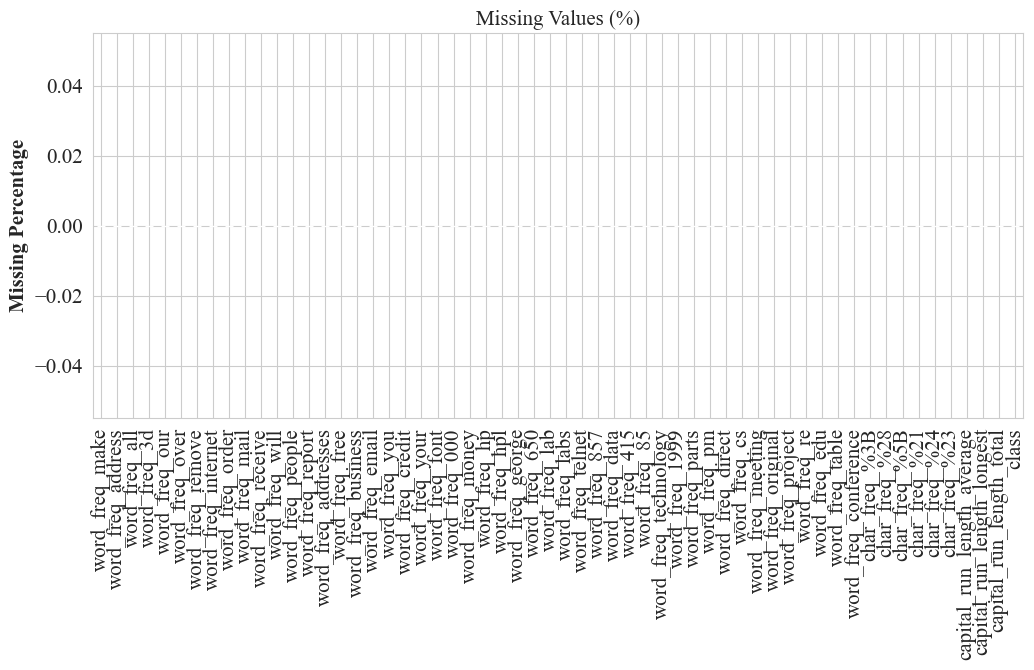



DUPLICATE ANALYSIS
Duplicate Rows       : 391
Duplicate Percentage : 8.50%


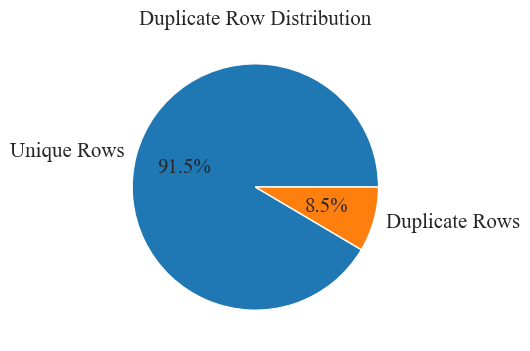



NUMERICAL FEATURE ANALYSIS

--------------------------------------------------------------------------------
Column : word_freq_make
--------------------------------------------------------------------------------
Mean       : 0.105
Median     : 0.000
Std Dev    : 0.305
Variance   : 0.093
Skewness   : 5.676
Kurtosis   : 49.305


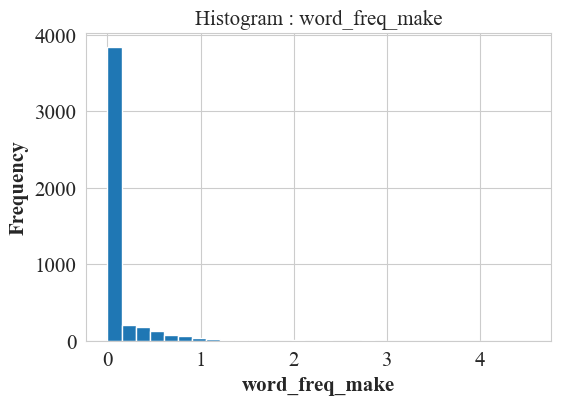

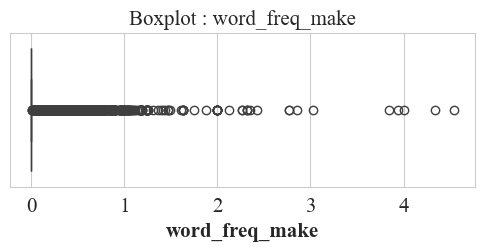

Outliers Detected : 1053

--------------------------------------------------------------------------------
Column : word_freq_address
--------------------------------------------------------------------------------
Mean       : 0.213
Median     : 0.000
Std Dev    : 1.291
Variance   : 1.666
Skewness   : 10.087
Kurtosis   : 105.647


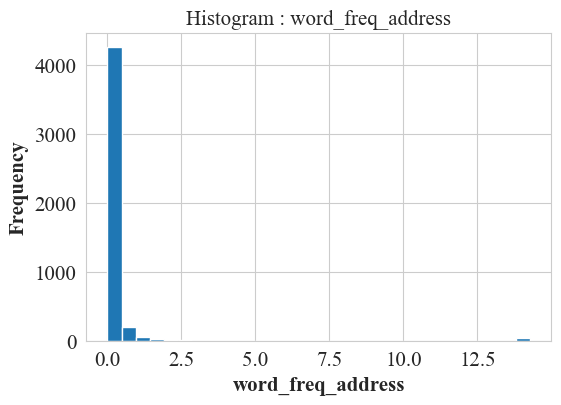

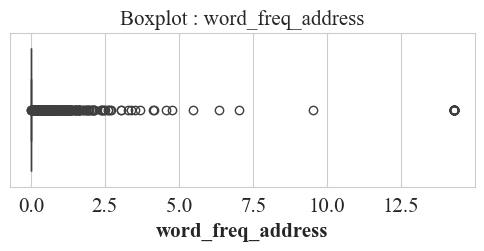

Outliers Detected : 898

--------------------------------------------------------------------------------
Column : word_freq_all
--------------------------------------------------------------------------------
Mean       : 0.281
Median     : 0.000
Std Dev    : 0.504
Variance   : 0.254
Skewness   : 3.009
Kurtosis   : 13.309


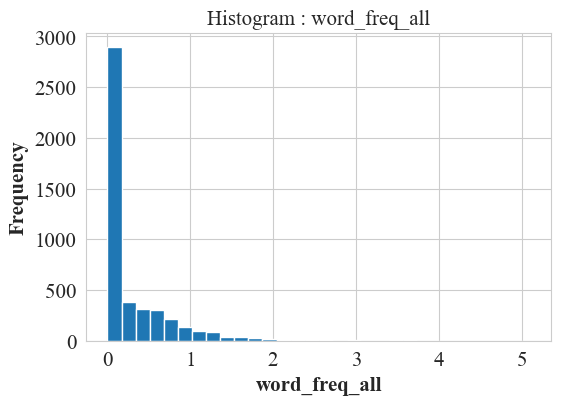

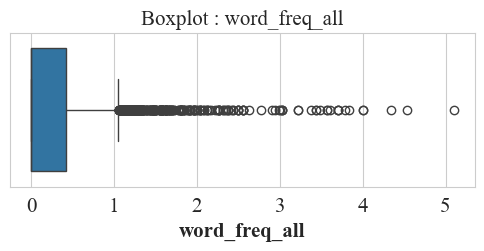

Outliers Detected : 338

--------------------------------------------------------------------------------
Column : word_freq_3d
--------------------------------------------------------------------------------
Mean       : 0.065
Median     : 0.000
Std Dev    : 1.395
Variance   : 1.946
Skewness   : 26.228
Kurtosis   : 726.452


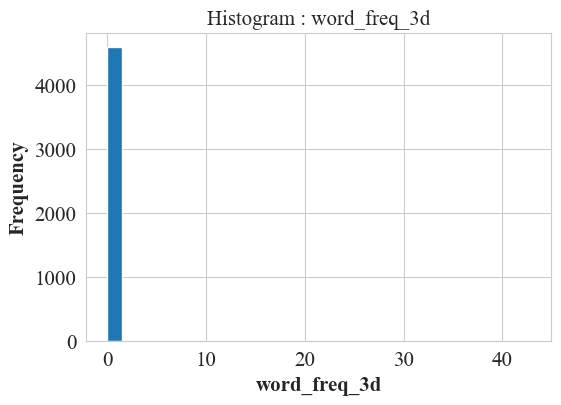

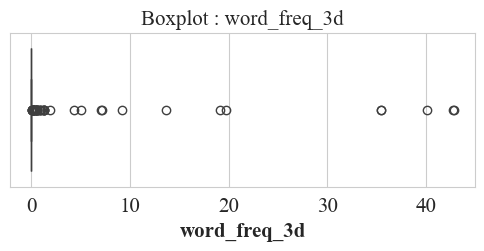

Outliers Detected : 47

--------------------------------------------------------------------------------
Column : word_freq_our
--------------------------------------------------------------------------------
Mean       : 0.312
Median     : 0.000
Std Dev    : 0.673
Variance   : 0.452
Skewness   : 4.747
Kurtosis   : 37.941


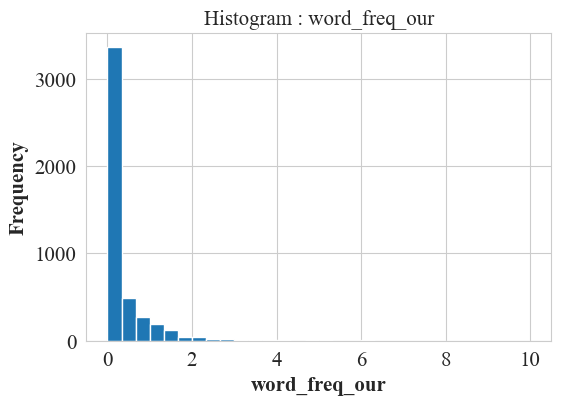

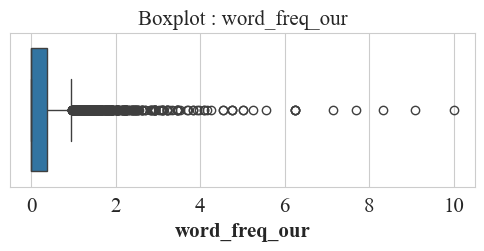

Outliers Detected : 501

--------------------------------------------------------------------------------
Column : word_freq_over
--------------------------------------------------------------------------------
Mean       : 0.096
Median     : 0.000
Std Dev    : 0.274
Variance   : 0.075
Skewness   : 5.957
Kurtosis   : 68.445


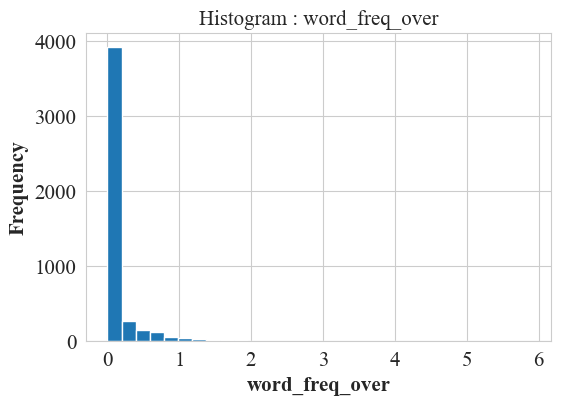

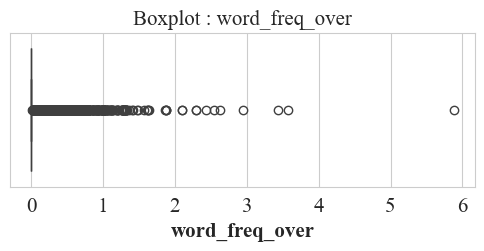

Outliers Detected : 999

--------------------------------------------------------------------------------
Column : word_freq_remove
--------------------------------------------------------------------------------
Mean       : 0.114
Median     : 0.000
Std Dev    : 0.391
Variance   : 0.153
Skewness   : 6.766
Kurtosis   : 75.413


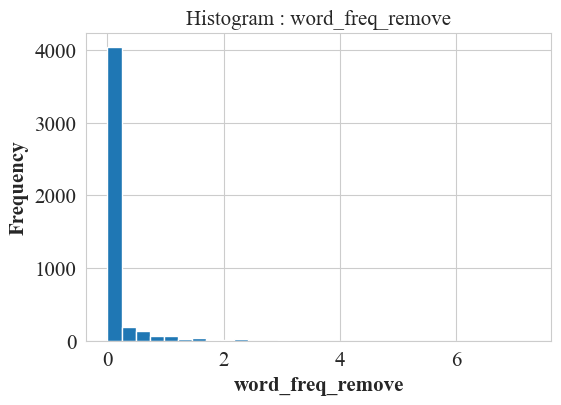

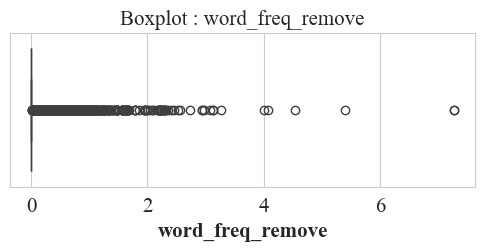

Outliers Detected : 807

--------------------------------------------------------------------------------
Column : word_freq_internet
--------------------------------------------------------------------------------
Mean       : 0.105
Median     : 0.000
Std Dev    : 0.401
Variance   : 0.161
Skewness   : 9.725
Kurtosis   : 169.163


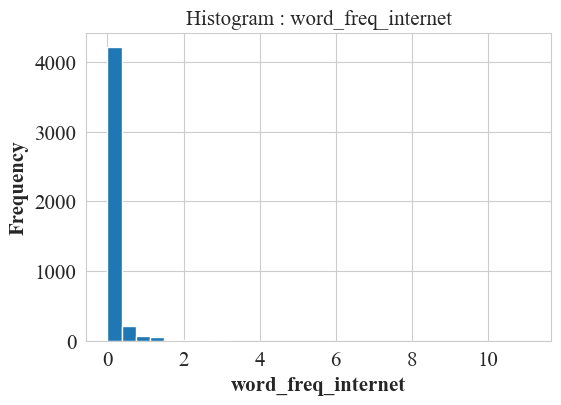

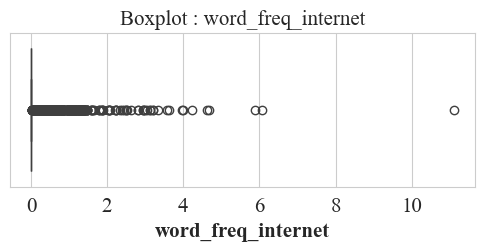

Outliers Detected : 824

--------------------------------------------------------------------------------
Column : word_freq_order
--------------------------------------------------------------------------------
Mean       : 0.090
Median     : 0.000
Std Dev    : 0.279
Variance   : 0.078
Skewness   : 5.226
Kurtosis   : 46.940


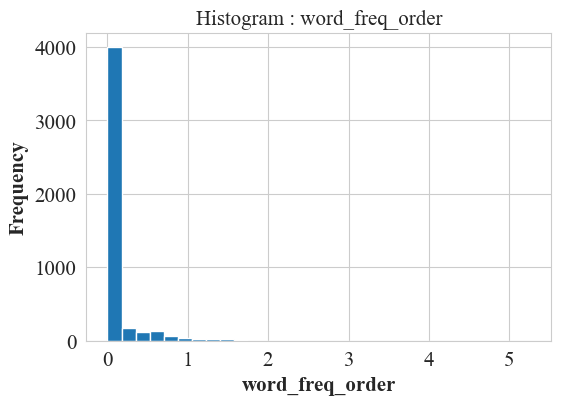

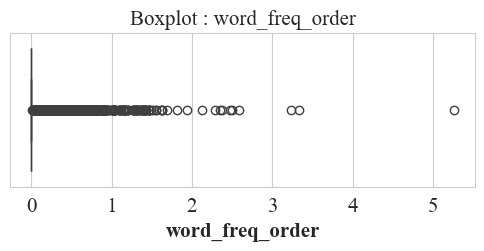

Outliers Detected : 773

--------------------------------------------------------------------------------
Column : word_freq_mail
--------------------------------------------------------------------------------
Mean       : 0.239
Median     : 0.000
Std Dev    : 0.645
Variance   : 0.416
Skewness   : 8.488
Kurtosis   : 161.215


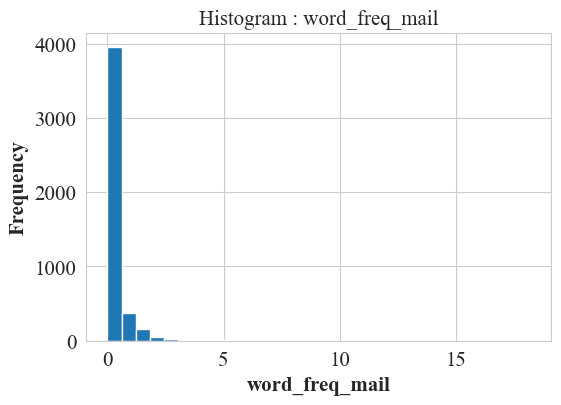

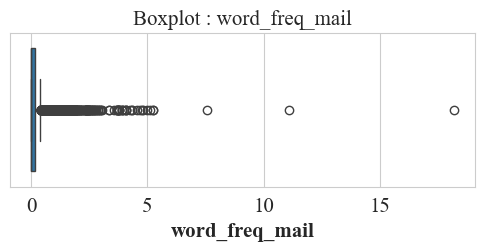

Outliers Detected : 852

--------------------------------------------------------------------------------
Column : word_freq_receive
--------------------------------------------------------------------------------
Mean       : 0.060
Median     : 0.000
Std Dev    : 0.202
Variance   : 0.041
Skewness   : 5.510
Kurtosis   : 39.651


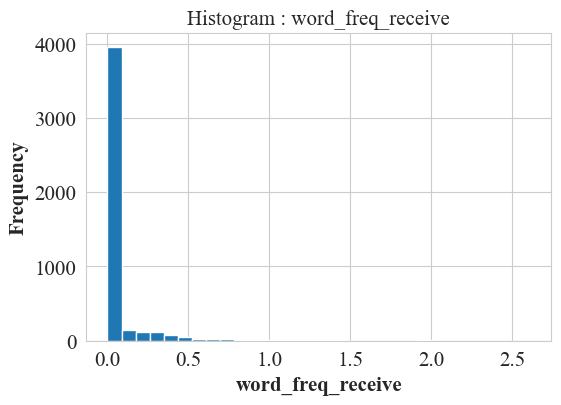

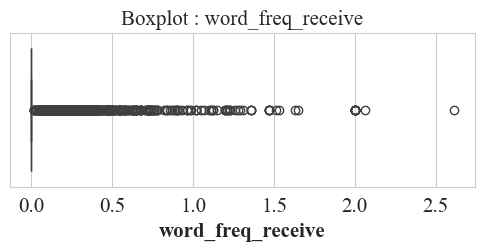

Outliers Detected : 709

--------------------------------------------------------------------------------
Column : word_freq_will
--------------------------------------------------------------------------------
Mean       : 0.542
Median     : 0.100
Std Dev    : 0.862
Variance   : 0.743
Skewness   : 2.867
Kurtosis   : 12.551


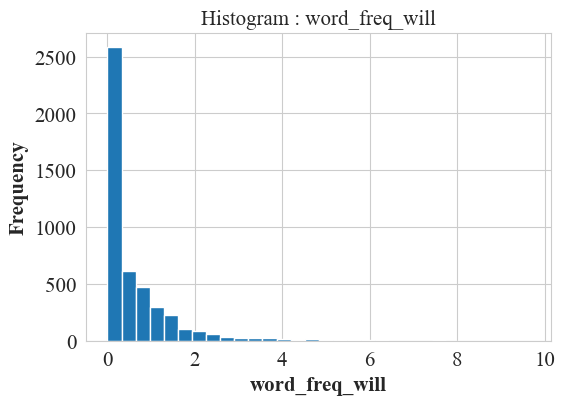

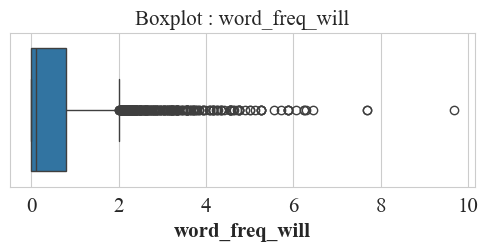

Outliers Detected : 270

--------------------------------------------------------------------------------
Column : word_freq_people
--------------------------------------------------------------------------------
Mean       : 0.094
Median     : 0.000
Std Dev    : 0.301
Variance   : 0.091
Skewness   : 6.956
Kurtosis   : 84.942


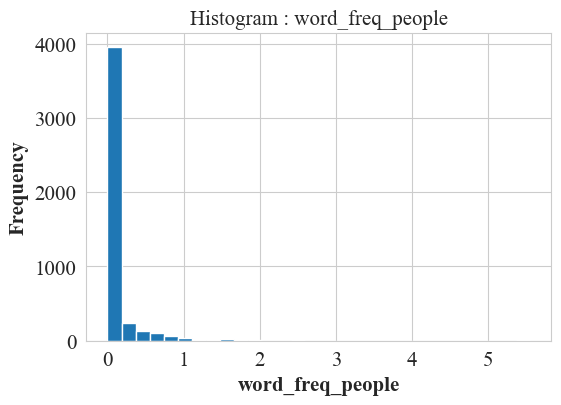

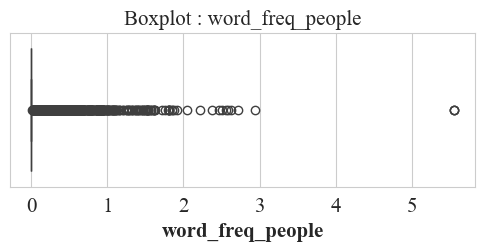

Outliers Detected : 852

--------------------------------------------------------------------------------
Column : word_freq_report
--------------------------------------------------------------------------------
Mean       : 0.059
Median     : 0.000
Std Dev    : 0.335
Variance   : 0.112
Skewness   : 11.755
Kurtosis   : 229.201


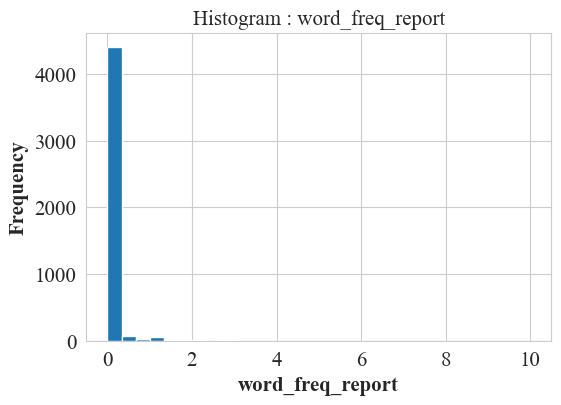

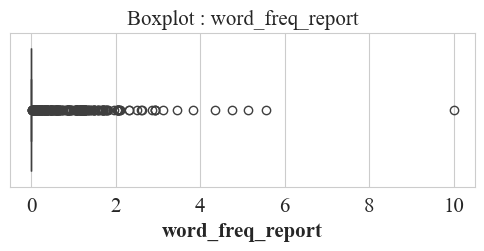

Outliers Detected : 357

--------------------------------------------------------------------------------
Column : word_freq_addresses
--------------------------------------------------------------------------------
Mean       : 0.049
Median     : 0.000
Std Dev    : 0.259
Variance   : 0.067
Skewness   : 6.971
Kurtosis   : 57.728


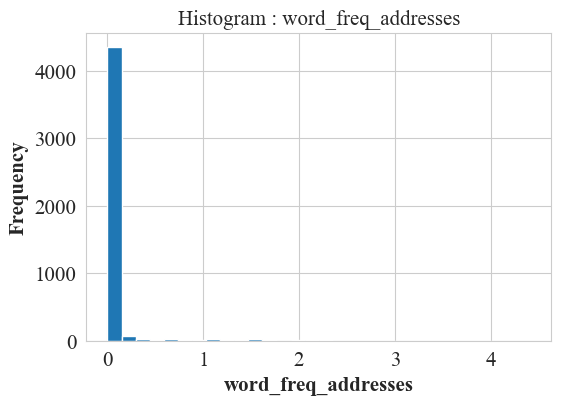

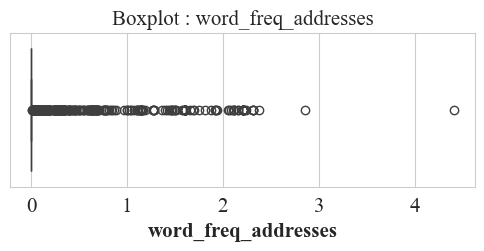

Outliers Detected : 336

--------------------------------------------------------------------------------
Column : word_freq_free
--------------------------------------------------------------------------------
Mean       : 0.249
Median     : 0.000
Std Dev    : 0.826
Variance   : 0.682
Skewness   : 10.764
Kurtosis   : 196.425


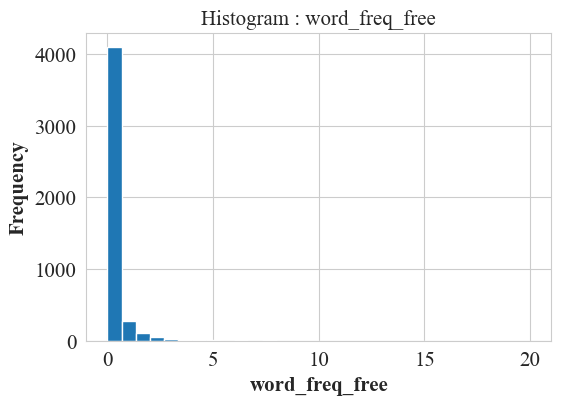

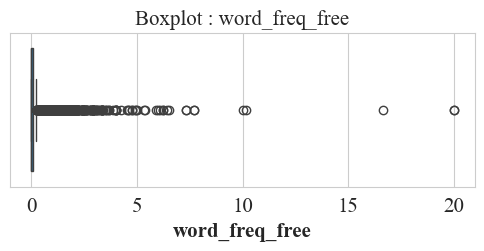

Outliers Detected : 957

--------------------------------------------------------------------------------
Column : word_freq_business
--------------------------------------------------------------------------------
Mean       : 0.143
Median     : 0.000
Std Dev    : 0.444
Variance   : 0.197
Skewness   : 5.689
Kurtosis   : 45.674


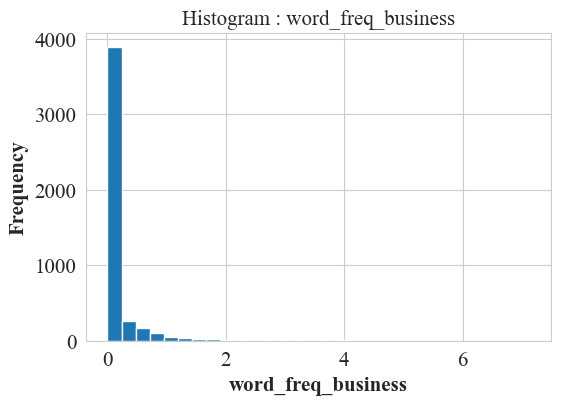

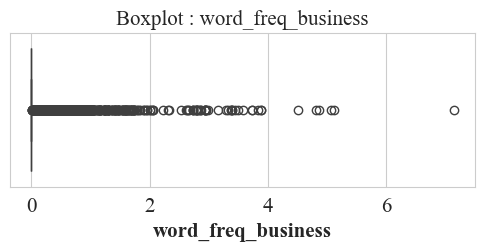

Outliers Detected : 963

--------------------------------------------------------------------------------
Column : word_freq_email
--------------------------------------------------------------------------------
Mean       : 0.185
Median     : 0.000
Std Dev    : 0.531
Variance   : 0.282
Skewness   : 5.414
Kurtosis   : 47.962


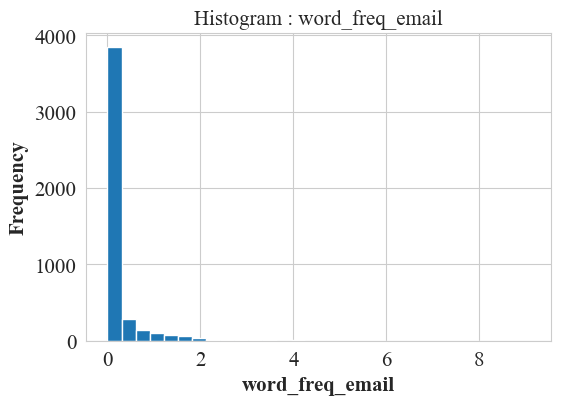

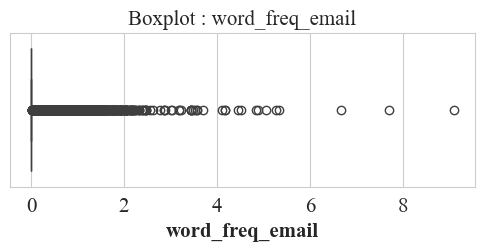

Outliers Detected : 1038

--------------------------------------------------------------------------------
Column : word_freq_you
--------------------------------------------------------------------------------
Mean       : 1.662
Median     : 1.310
Std Dev    : 1.775
Variance   : 3.152
Skewness   : 1.592
Kurtosis   : 5.257


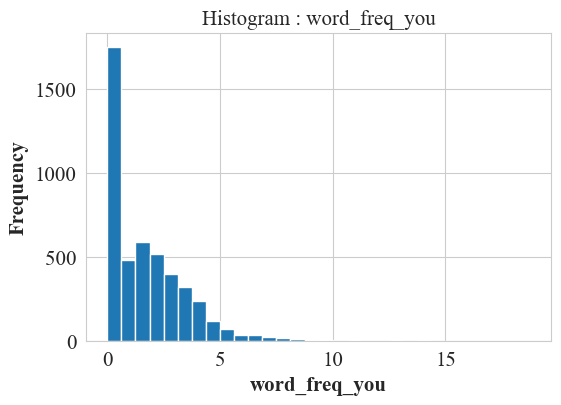

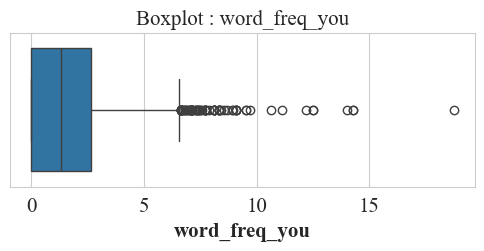

Outliers Detected : 75

--------------------------------------------------------------------------------
Column : word_freq_credit
--------------------------------------------------------------------------------
Mean       : 0.086
Median     : 0.000
Std Dev    : 0.510
Variance   : 0.260
Skewness   : 14.603
Kurtosis   : 383.002


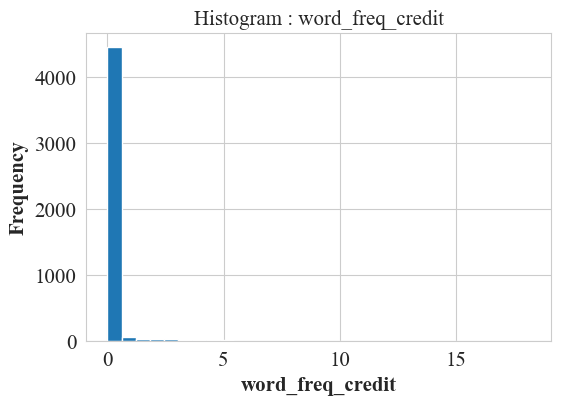

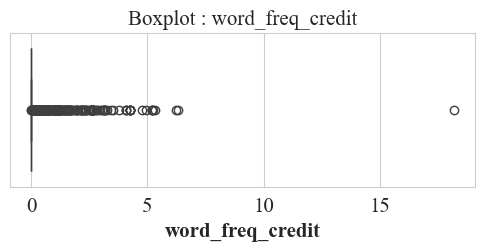

Outliers Detected : 424

--------------------------------------------------------------------------------
Column : word_freq_your
--------------------------------------------------------------------------------
Mean       : 0.810
Median     : 0.220
Std Dev    : 1.201
Variance   : 1.442
Skewness   : 2.436
Kurtosis   : 9.010


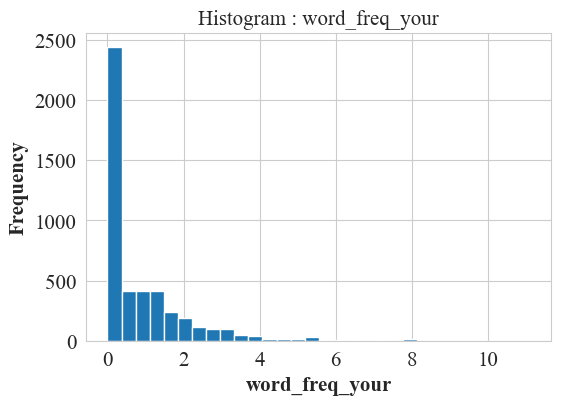

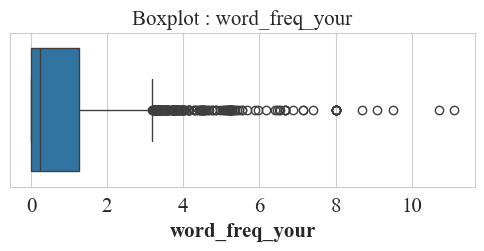

Outliers Detected : 229

--------------------------------------------------------------------------------
Column : word_freq_font
--------------------------------------------------------------------------------
Mean       : 0.121
Median     : 0.000
Std Dev    : 1.026
Variance   : 1.052
Skewness   : 9.975
Kurtosis   : 109.142


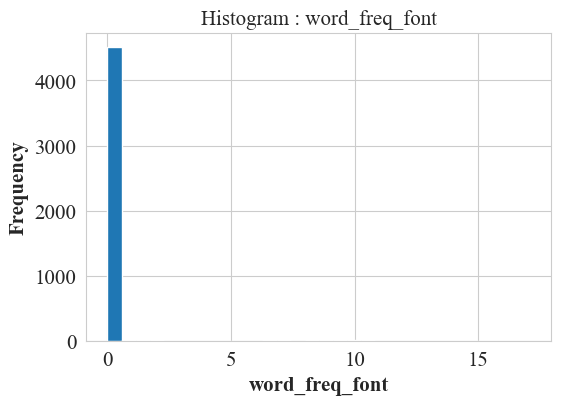

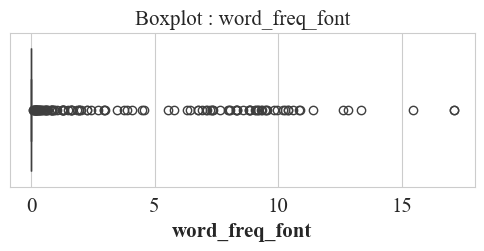

Outliers Detected : 117

--------------------------------------------------------------------------------
Column : word_freq_000
--------------------------------------------------------------------------------
Mean       : 0.102
Median     : 0.000
Std Dev    : 0.350
Variance   : 0.123
Skewness   : 5.714
Kurtosis   : 46.808


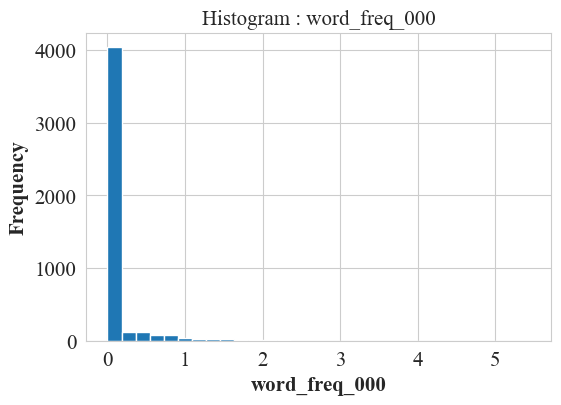

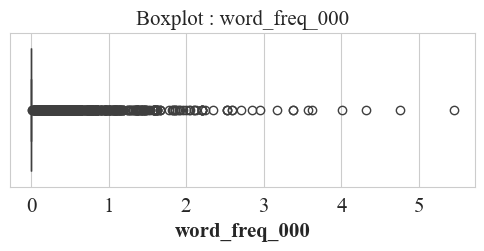

Outliers Detected : 679

--------------------------------------------------------------------------------
Column : word_freq_money
--------------------------------------------------------------------------------
Mean       : 0.094
Median     : 0.000
Std Dev    : 0.443
Variance   : 0.196
Skewness   : 14.687
Kurtosis   : 302.056


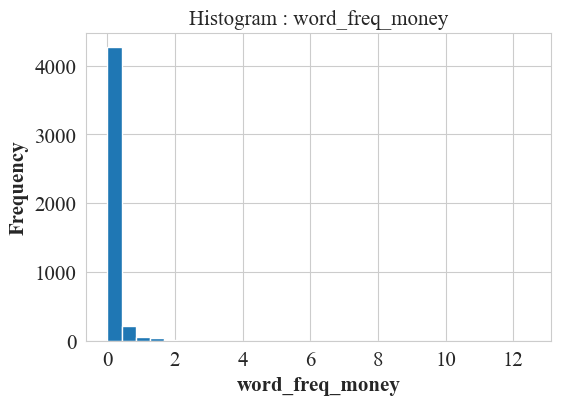

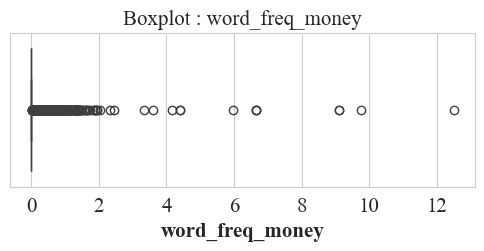

Outliers Detected : 735

--------------------------------------------------------------------------------
Column : word_freq_hp
--------------------------------------------------------------------------------
Mean       : 0.550
Median     : 0.000
Std Dev    : 1.671
Variance   : 2.793
Skewness   : 5.717
Kurtosis   : 43.604


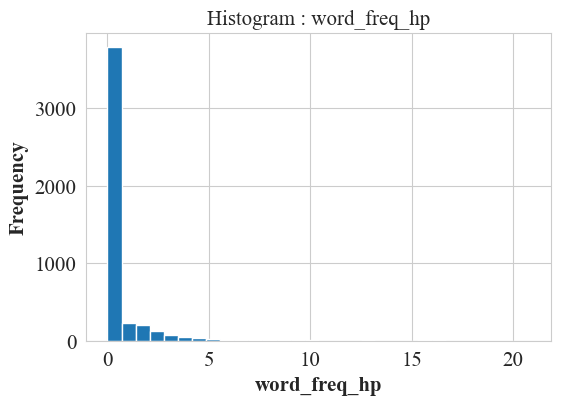

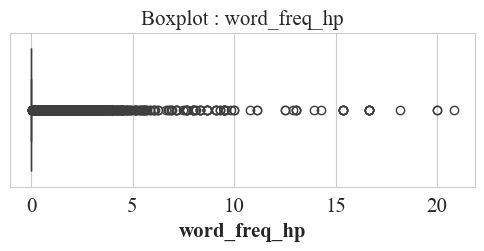

Outliers Detected : 1090

--------------------------------------------------------------------------------
Column : word_freq_hpl
--------------------------------------------------------------------------------
Mean       : 0.265
Median     : 0.000
Std Dev    : 0.887
Variance   : 0.787
Skewness   : 6.350
Kurtosis   : 63.900


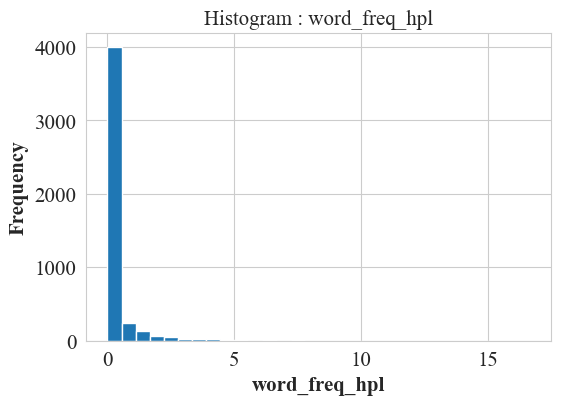

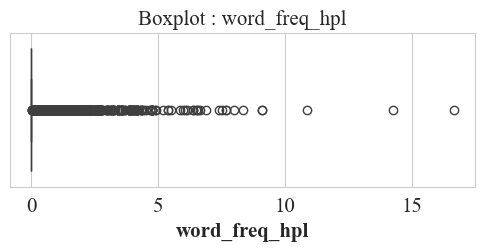

Outliers Detected : 811

--------------------------------------------------------------------------------
Column : word_freq_george
--------------------------------------------------------------------------------
Mean       : 0.767
Median     : 0.000
Std Dev    : 3.367
Variance   : 11.339
Skewness   : 5.744
Kurtosis   : 34.204


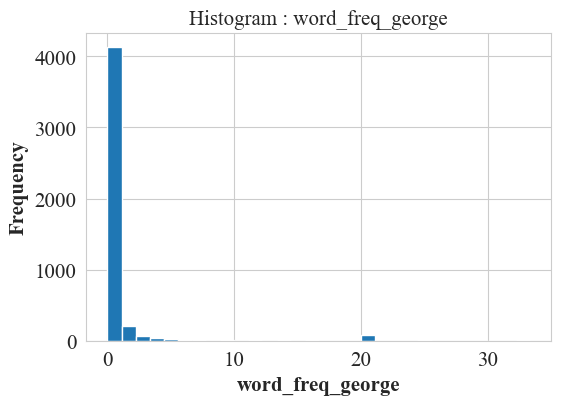

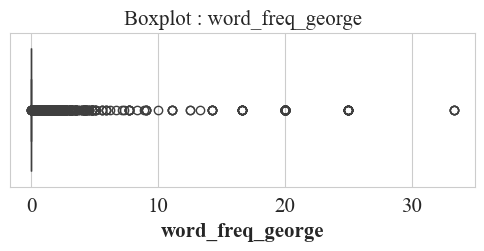

Outliers Detected : 780

--------------------------------------------------------------------------------
Column : word_freq_650
--------------------------------------------------------------------------------
Mean       : 0.125
Median     : 0.000
Std Dev    : 0.539
Variance   : 0.290
Skewness   : 6.607
Kurtosis   : 58.373


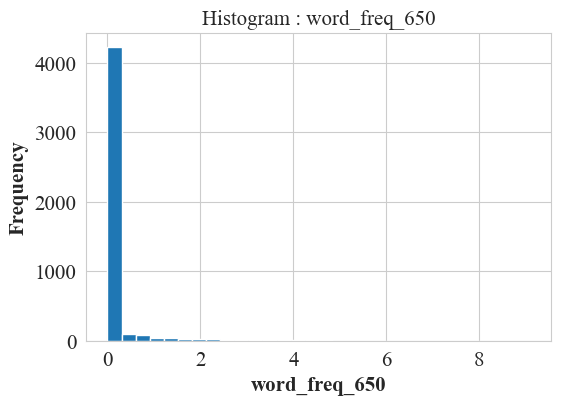

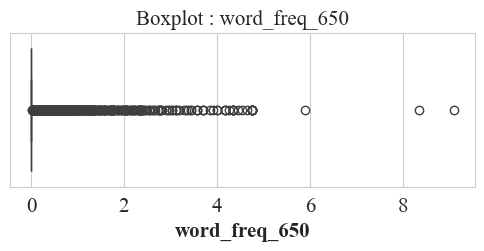

Outliers Detected : 463

--------------------------------------------------------------------------------
Column : word_freq_lab
--------------------------------------------------------------------------------
Mean       : 0.099
Median     : 0.000
Std Dev    : 0.593
Variance   : 0.352
Skewness   : 11.370
Kurtosis   : 175.248


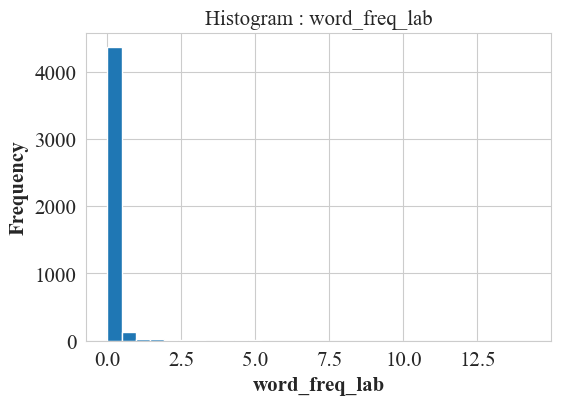

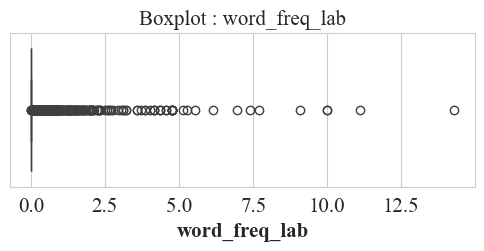

Outliers Detected : 372

--------------------------------------------------------------------------------
Column : word_freq_labs
--------------------------------------------------------------------------------
Mean       : 0.103
Median     : 0.000
Std Dev    : 0.457
Variance   : 0.209
Skewness   : 6.636
Kurtosis   : 52.007


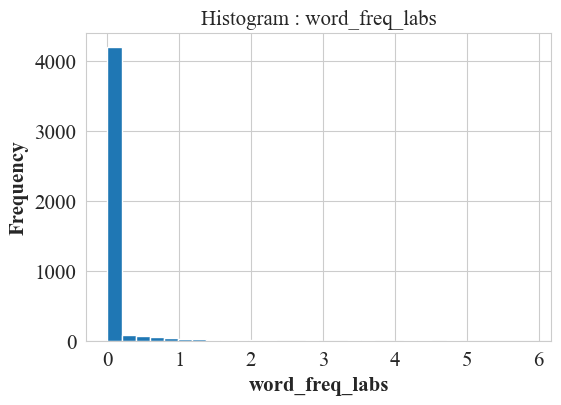

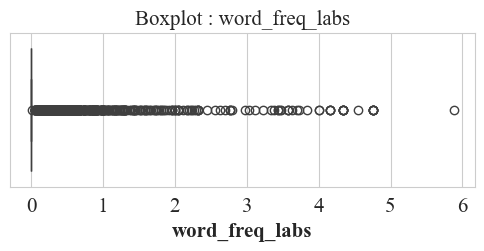

Outliers Detected : 469

--------------------------------------------------------------------------------
Column : word_freq_telnet
--------------------------------------------------------------------------------
Mean       : 0.065
Median     : 0.000
Std Dev    : 0.403
Variance   : 0.163
Skewness   : 12.669
Kurtosis   : 254.233


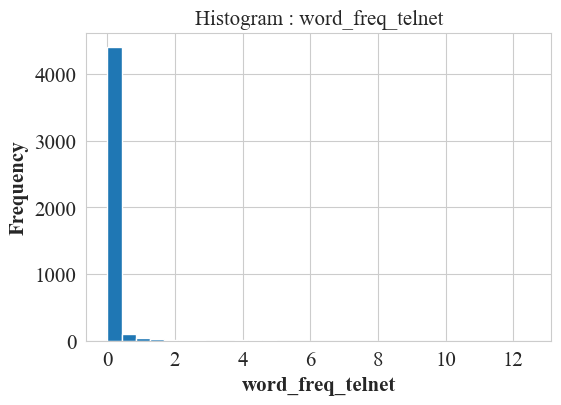

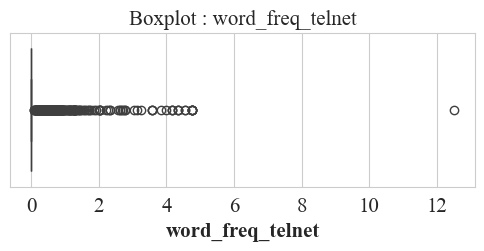

Outliers Detected : 293

--------------------------------------------------------------------------------
Column : word_freq_857
--------------------------------------------------------------------------------
Mean       : 0.047
Median     : 0.000
Std Dev    : 0.329
Variance   : 0.108
Skewness   : 10.549
Kurtosis   : 127.377


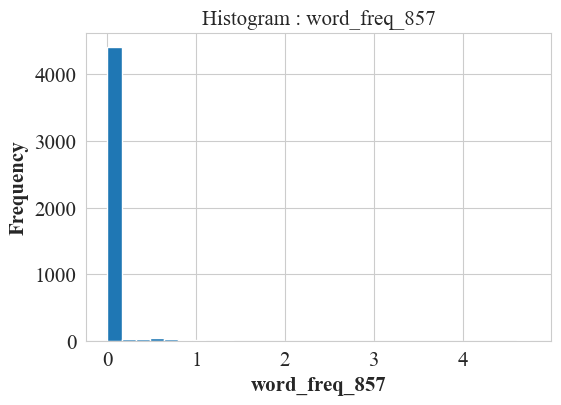

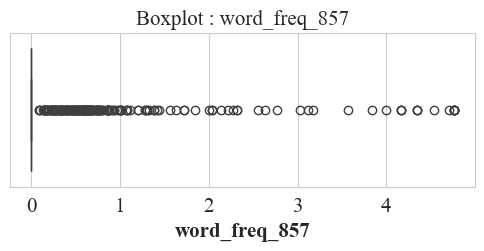

Outliers Detected : 205

--------------------------------------------------------------------------------
Column : word_freq_data
--------------------------------------------------------------------------------
Mean       : 0.097
Median     : 0.000
Std Dev    : 0.556
Variance   : 0.309
Skewness   : 13.190
Kurtosis   : 296.088


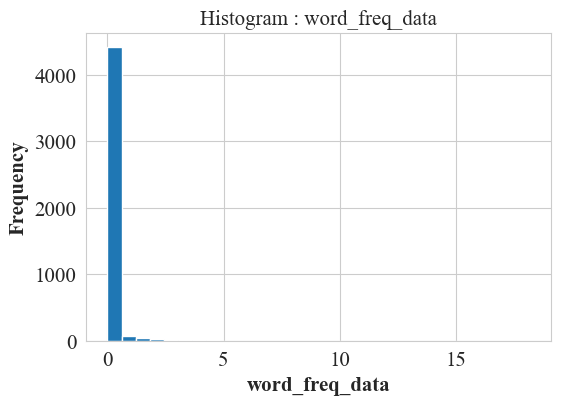

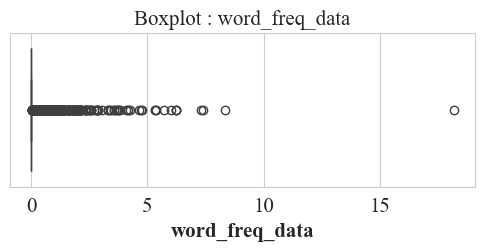

Outliers Detected : 405

--------------------------------------------------------------------------------
Column : word_freq_415
--------------------------------------------------------------------------------
Mean       : 0.048
Median     : 0.000
Std Dev    : 0.329
Variance   : 0.109
Skewness   : 10.475
Kurtosis   : 125.943


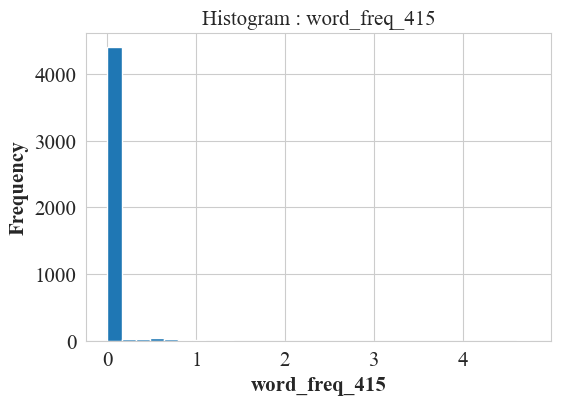

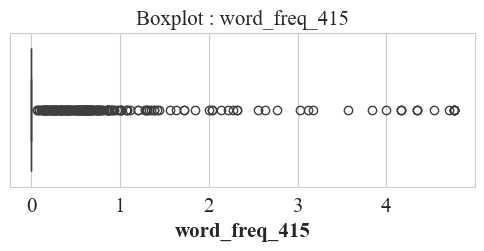

Outliers Detected : 215

--------------------------------------------------------------------------------
Column : word_freq_85
--------------------------------------------------------------------------------
Mean       : 0.105
Median     : 0.000
Std Dev    : 0.532
Variance   : 0.283
Skewness   : 15.231
Kurtosis   : 449.374


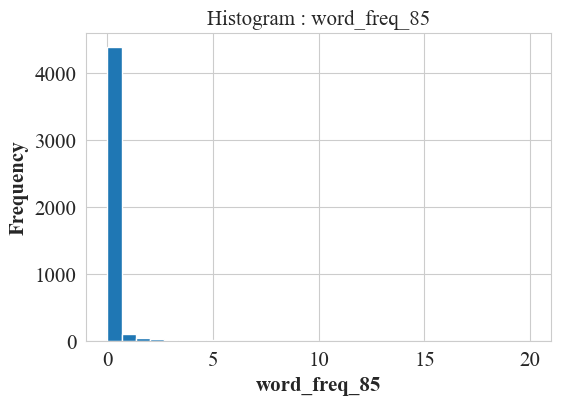

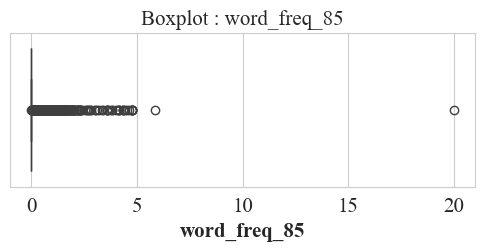

Outliers Detected : 485

--------------------------------------------------------------------------------
Column : word_freq_technology
--------------------------------------------------------------------------------
Mean       : 0.097
Median     : 0.000
Std Dev    : 0.403
Variance   : 0.162
Skewness   : 7.673
Kurtosis   : 81.207


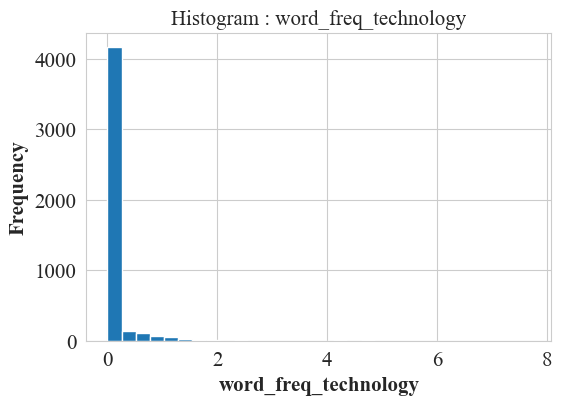

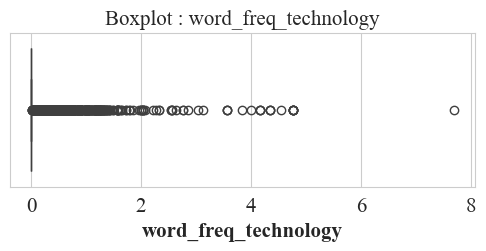

Outliers Detected : 599

--------------------------------------------------------------------------------
Column : word_freq_1999
--------------------------------------------------------------------------------
Mean       : 0.137
Median     : 0.000
Std Dev    : 0.423
Variance   : 0.179
Skewness   : 5.323
Kurtosis   : 42.621


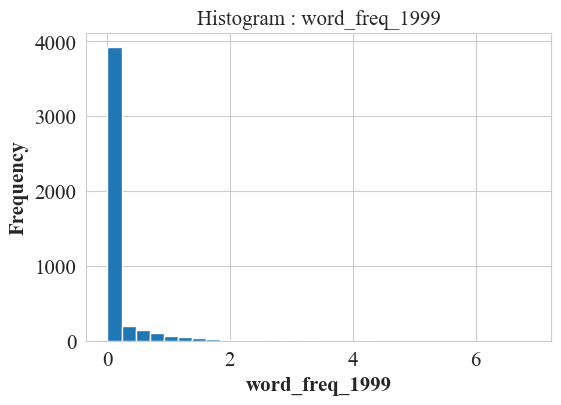

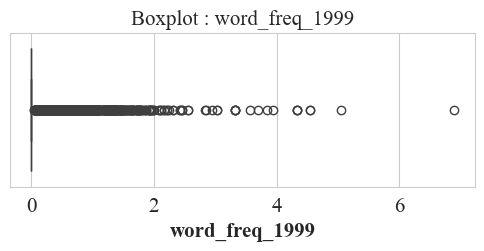

Outliers Detected : 829

--------------------------------------------------------------------------------
Column : word_freq_parts
--------------------------------------------------------------------------------
Mean       : 0.013
Median     : 0.000
Std Dev    : 0.221
Variance   : 0.049
Skewness   : 28.263
Kurtosis   : 912.046


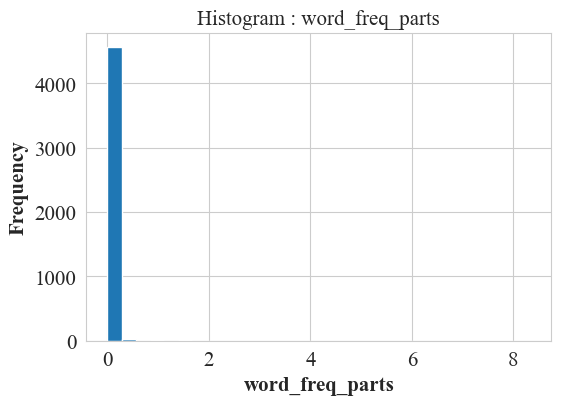

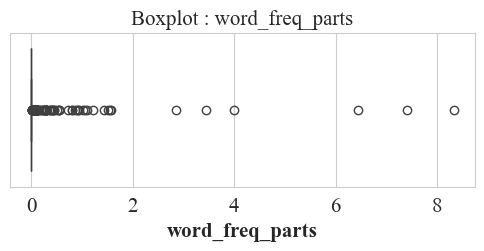

Outliers Detected : 83

--------------------------------------------------------------------------------
Column : word_freq_pm
--------------------------------------------------------------------------------
Mean       : 0.079
Median     : 0.000
Std Dev    : 0.435
Variance   : 0.189
Skewness   : 12.057
Kurtosis   : 215.718


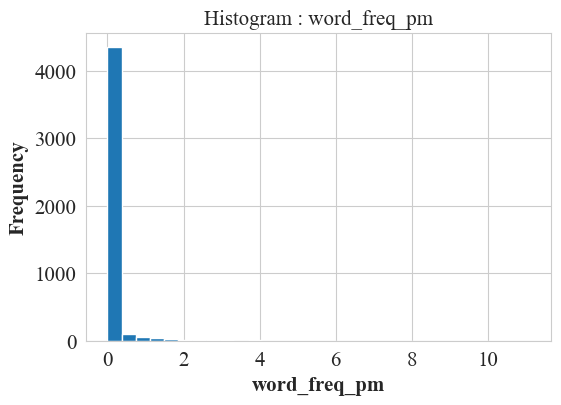

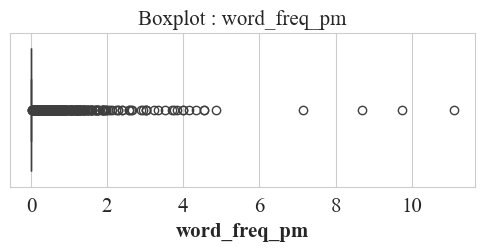

Outliers Detected : 384

--------------------------------------------------------------------------------
Column : word_freq_direct
--------------------------------------------------------------------------------
Mean       : 0.065
Median     : 0.000
Std Dev    : 0.350
Variance   : 0.122
Skewness   : 9.147
Kurtosis   : 99.387


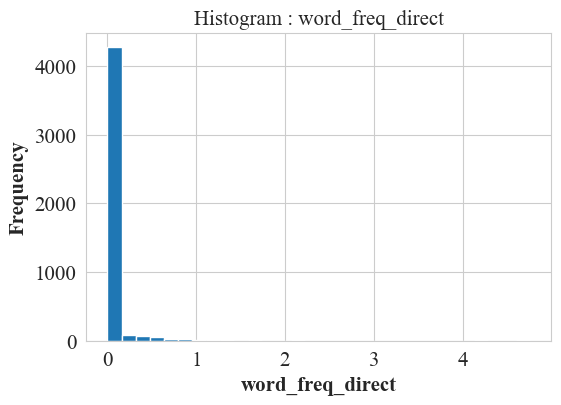

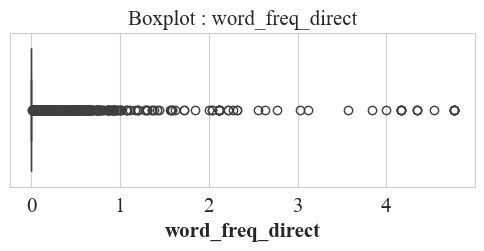

Outliers Detected : 453

--------------------------------------------------------------------------------
Column : word_freq_cs
--------------------------------------------------------------------------------
Mean       : 0.044
Median     : 0.000
Std Dev    : 0.361
Variance   : 0.130
Skewness   : 12.588
Kurtosis   : 193.619


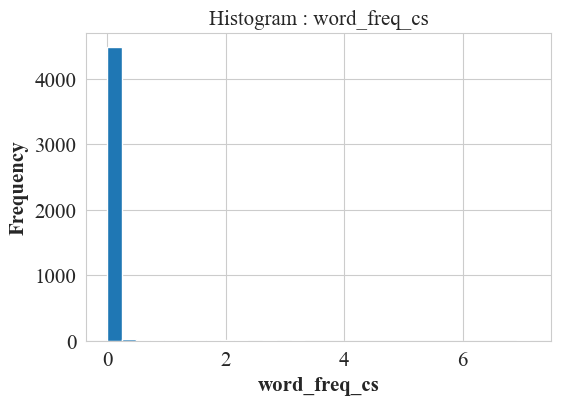

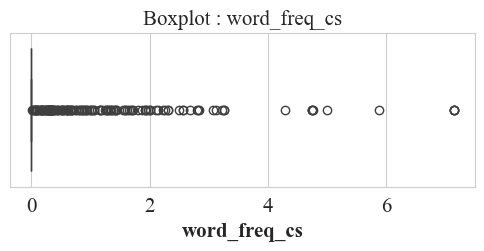

Outliers Detected : 148

--------------------------------------------------------------------------------
Column : word_freq_meeting
--------------------------------------------------------------------------------
Mean       : 0.132
Median     : 0.000
Std Dev    : 0.767
Variance   : 0.588
Skewness   : 9.456
Kurtosis   : 115.706


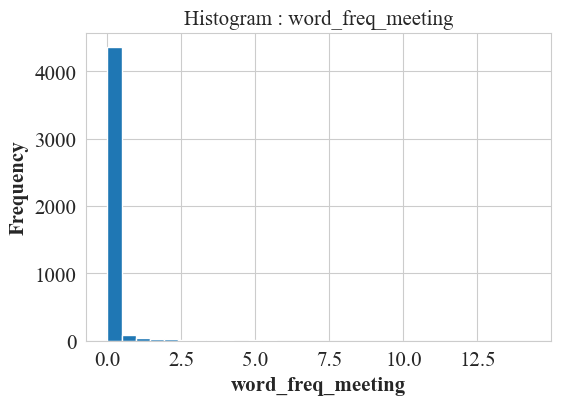

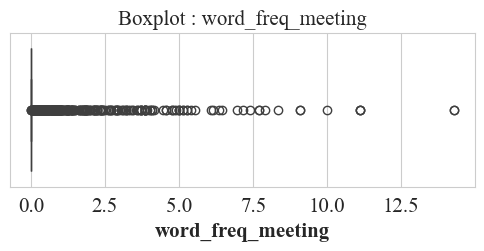

Outliers Detected : 341

--------------------------------------------------------------------------------
Column : word_freq_original
--------------------------------------------------------------------------------
Mean       : 0.046
Median     : 0.000
Std Dev    : 0.224
Variance   : 0.050
Skewness   : 7.629
Kurtosis   : 78.572


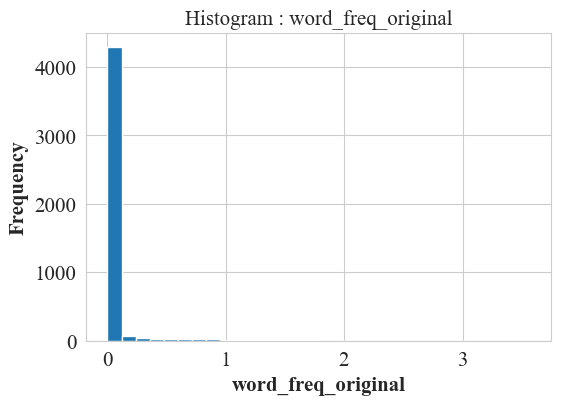

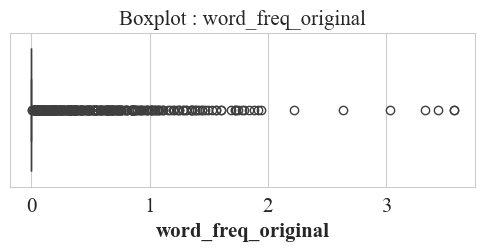

Outliers Detected : 375

--------------------------------------------------------------------------------
Column : word_freq_project
--------------------------------------------------------------------------------
Mean       : 0.079
Median     : 0.000
Std Dev    : 0.622
Variance   : 0.387
Skewness   : 18.772
Kurtosis   : 479.831


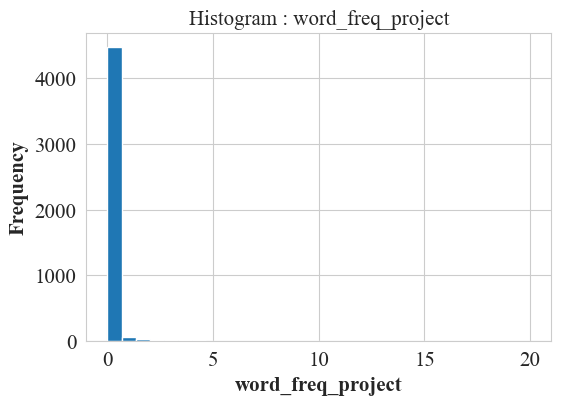

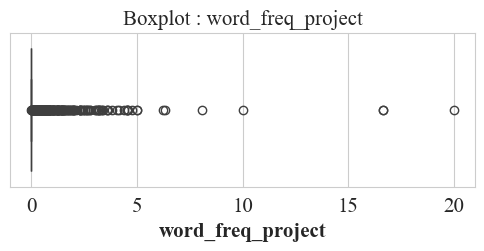

Outliers Detected : 327

--------------------------------------------------------------------------------
Column : word_freq_re
--------------------------------------------------------------------------------
Mean       : 0.301
Median     : 0.000
Std Dev    : 1.012
Variance   : 1.024
Skewness   : 9.146
Kurtosis   : 128.865


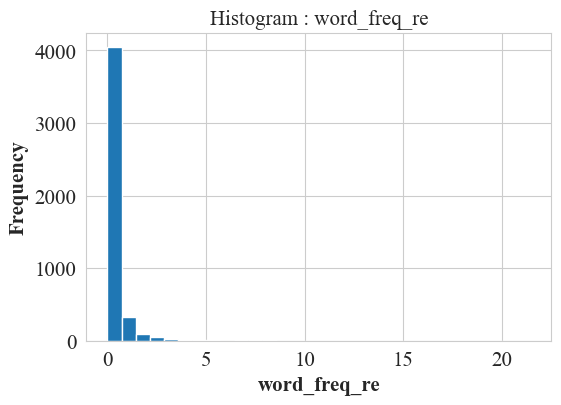

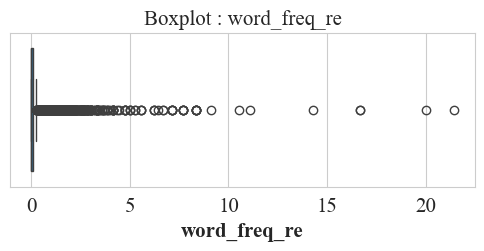

Outliers Detected : 1001

--------------------------------------------------------------------------------
Column : word_freq_edu
--------------------------------------------------------------------------------
Mean       : 0.180
Median     : 0.000
Std Dev    : 0.911
Variance   : 0.830
Skewness   : 10.123
Kurtosis   : 150.900


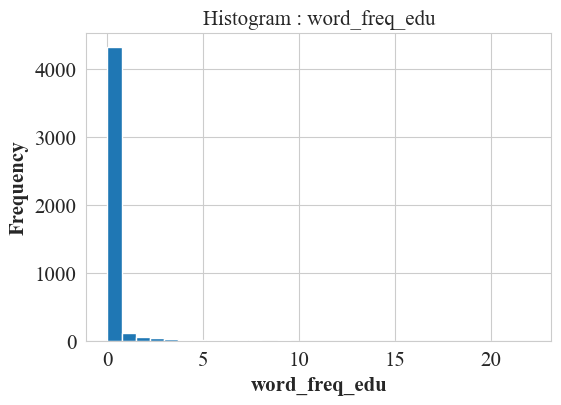

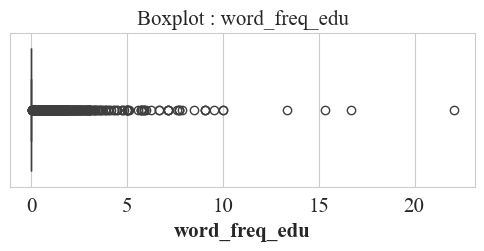

Outliers Detected : 517

--------------------------------------------------------------------------------
Column : word_freq_table
--------------------------------------------------------------------------------
Mean       : 0.005
Median     : 0.000
Std Dev    : 0.076
Variance   : 0.006
Skewness   : 19.868
Kurtosis   : 459.433


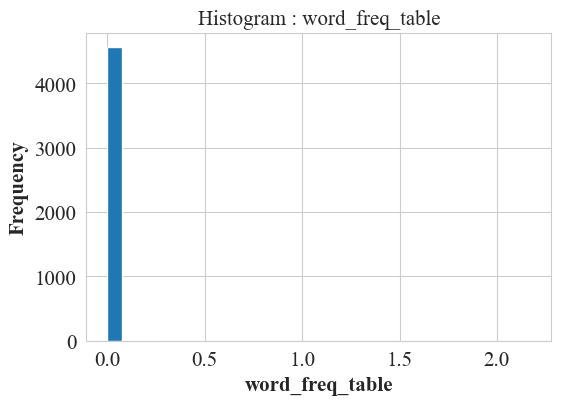

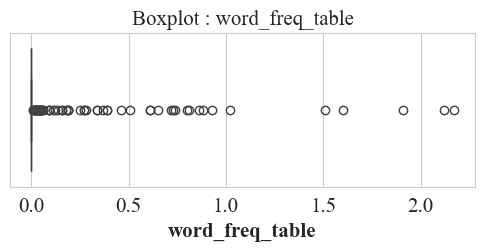

Outliers Detected : 63

--------------------------------------------------------------------------------
Column : word_freq_conference
--------------------------------------------------------------------------------
Mean       : 0.032
Median     : 0.000
Std Dev    : 0.286
Variance   : 0.082
Skewness   : 19.720
Kurtosis   : 537.493


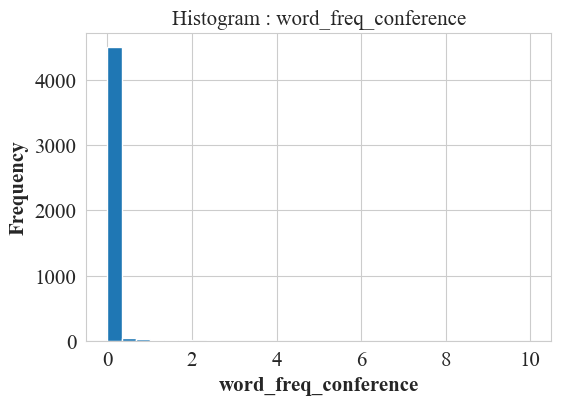

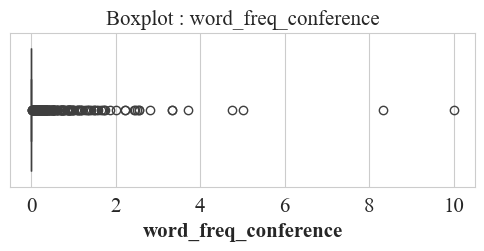

Outliers Detected : 203

--------------------------------------------------------------------------------
Column : char_freq_%3B
--------------------------------------------------------------------------------
Mean       : 0.039
Median     : 0.000
Std Dev    : 0.243
Variance   : 0.059
Skewness   : 13.709
Kurtosis   : 213.068


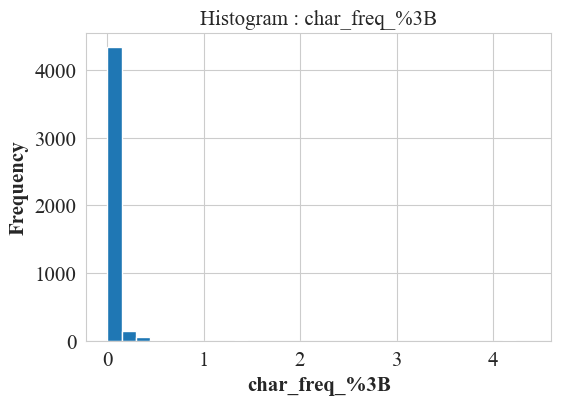

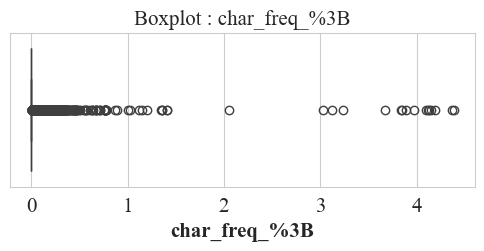

Outliers Detected : 790

--------------------------------------------------------------------------------
Column : char_freq_%28
--------------------------------------------------------------------------------
Mean       : 0.139
Median     : 0.065
Std Dev    : 0.270
Variance   : 0.073
Skewness   : 13.584
Kurtosis   : 393.415


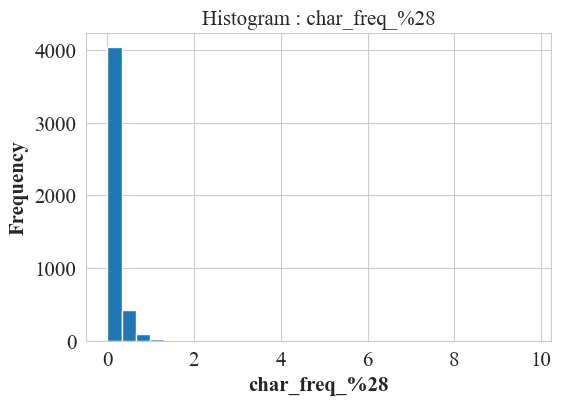

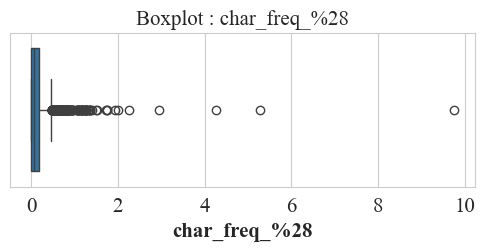

Outliers Detected : 296

--------------------------------------------------------------------------------
Column : char_freq_%5B
--------------------------------------------------------------------------------
Mean       : 0.017
Median     : 0.000
Std Dev    : 0.109
Variance   : 0.012
Skewness   : 21.084
Kurtosis   : 618.476


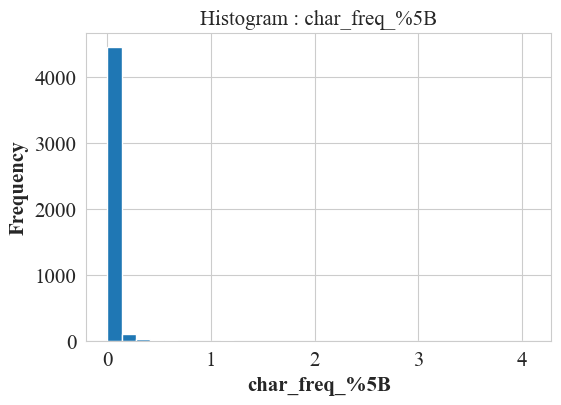

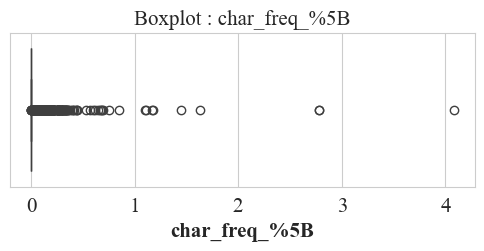

Outliers Detected : 529

--------------------------------------------------------------------------------
Column : char_freq_%21
--------------------------------------------------------------------------------
Mean       : 0.269
Median     : 0.000
Std Dev    : 0.816
Variance   : 0.665
Skewness   : 18.658
Kurtosis   : 607.456


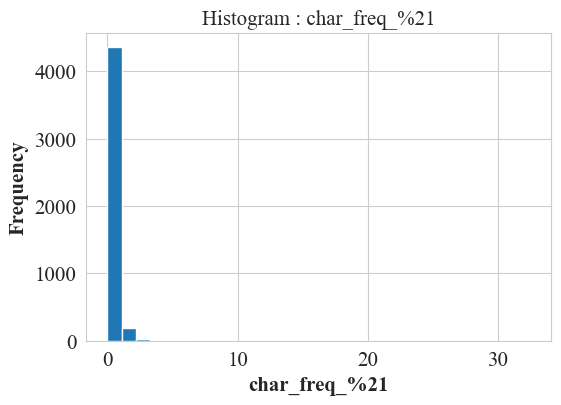

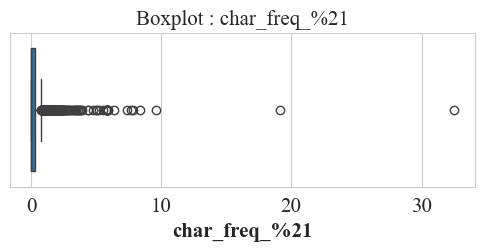

Outliers Detected : 411

--------------------------------------------------------------------------------
Column : char_freq_%24
--------------------------------------------------------------------------------
Mean       : 0.076
Median     : 0.000
Std Dev    : 0.246
Variance   : 0.060
Skewness   : 11.163
Kurtosis   : 199.954


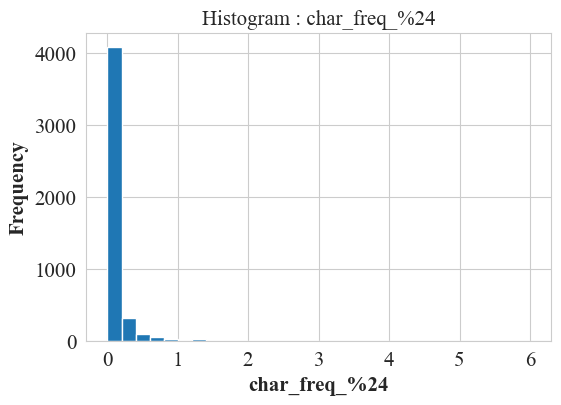

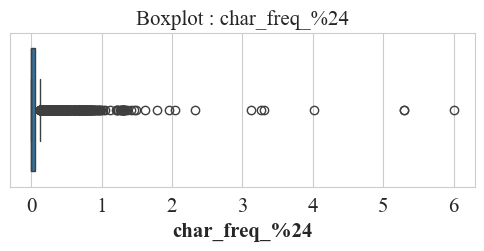

Outliers Detected : 811

--------------------------------------------------------------------------------
Column : char_freq_%23
--------------------------------------------------------------------------------
Mean       : 0.044
Median     : 0.000
Std Dev    : 0.429
Variance   : 0.184
Skewness   : 31.062
Kurtosis   : 1218.494


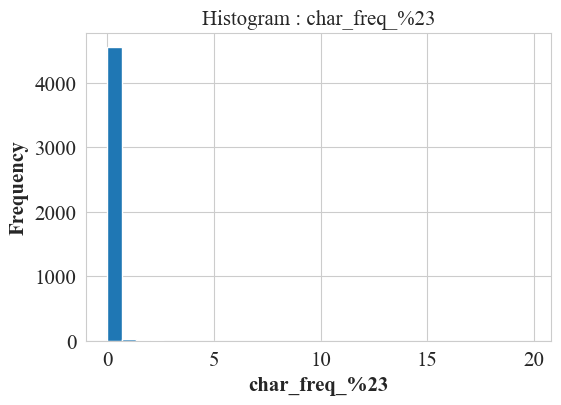

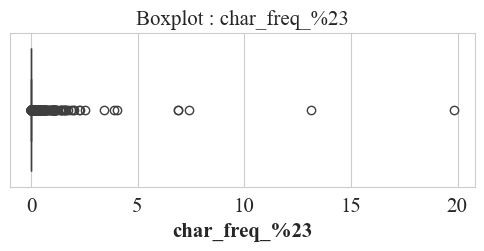

Outliers Detected : 750

--------------------------------------------------------------------------------
Column : capital_run_length_average
--------------------------------------------------------------------------------
Mean       : 5.192
Median     : 2.276
Std Dev    : 31.729
Variance   : 1006.758
Skewness   : 23.762
Kurtosis   : 670.369


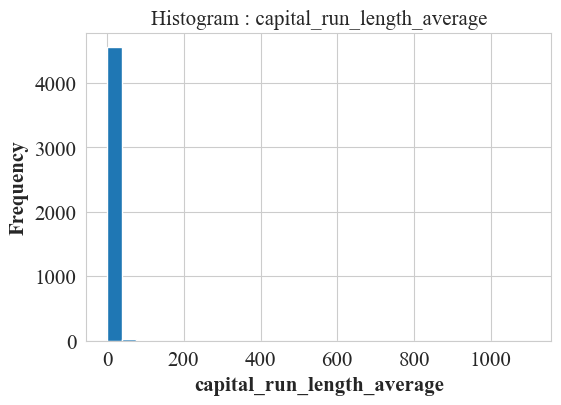

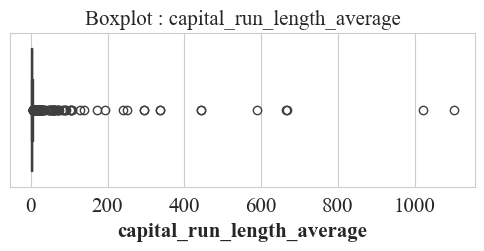

Outliers Detected : 363

--------------------------------------------------------------------------------
Column : capital_run_length_longest
--------------------------------------------------------------------------------
Mean       : 52.173
Median     : 15.000
Std Dev    : 194.891
Variance   : 37982.623
Skewness   : 30.765
Kurtosis   : 1480.642


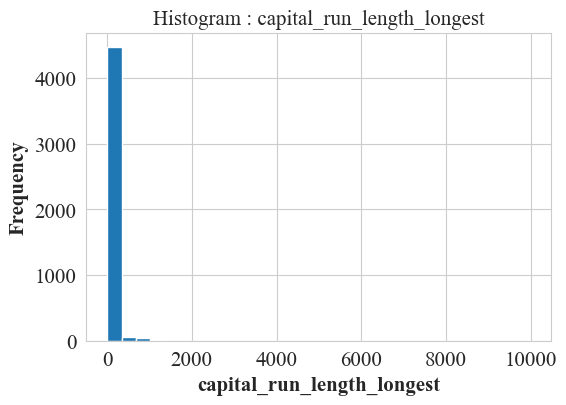

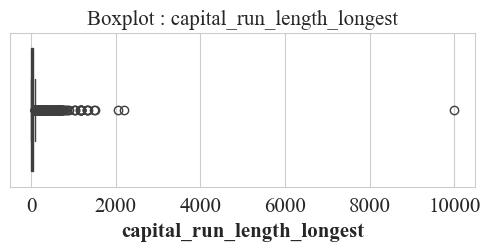

Outliers Detected : 463

--------------------------------------------------------------------------------
Column : capital_run_length_total
--------------------------------------------------------------------------------
Mean       : 283.289
Median     : 95.000
Std Dev    : 606.348
Variance   : 367657.716
Skewness   : 8.710
Kurtosis   : 145.830


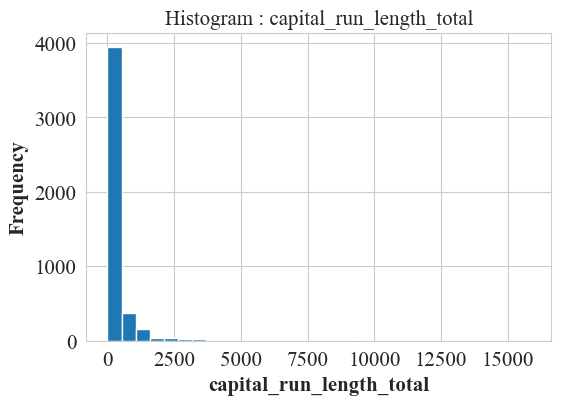

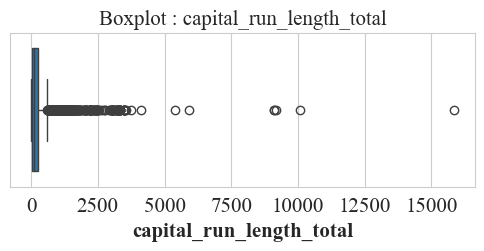

Outliers Detected : 550

--------------------------------------------------------------------------------
Column : class
--------------------------------------------------------------------------------
Mean       : 0.394
Median     : 0.000
Std Dev    : 0.489
Variance   : 0.239
Skewness   : 0.434
Kurtosis   : -1.813


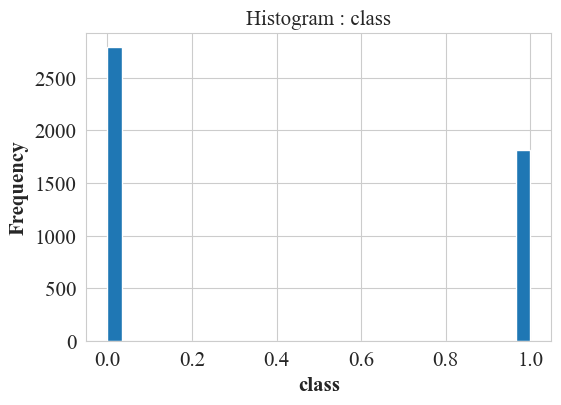

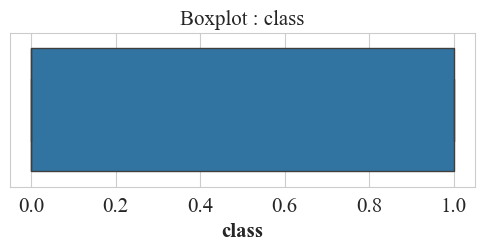

Outliers Detected : 0


CATEGORICAL FEATURE ANALYSIS


CORRELATION ANALYSIS


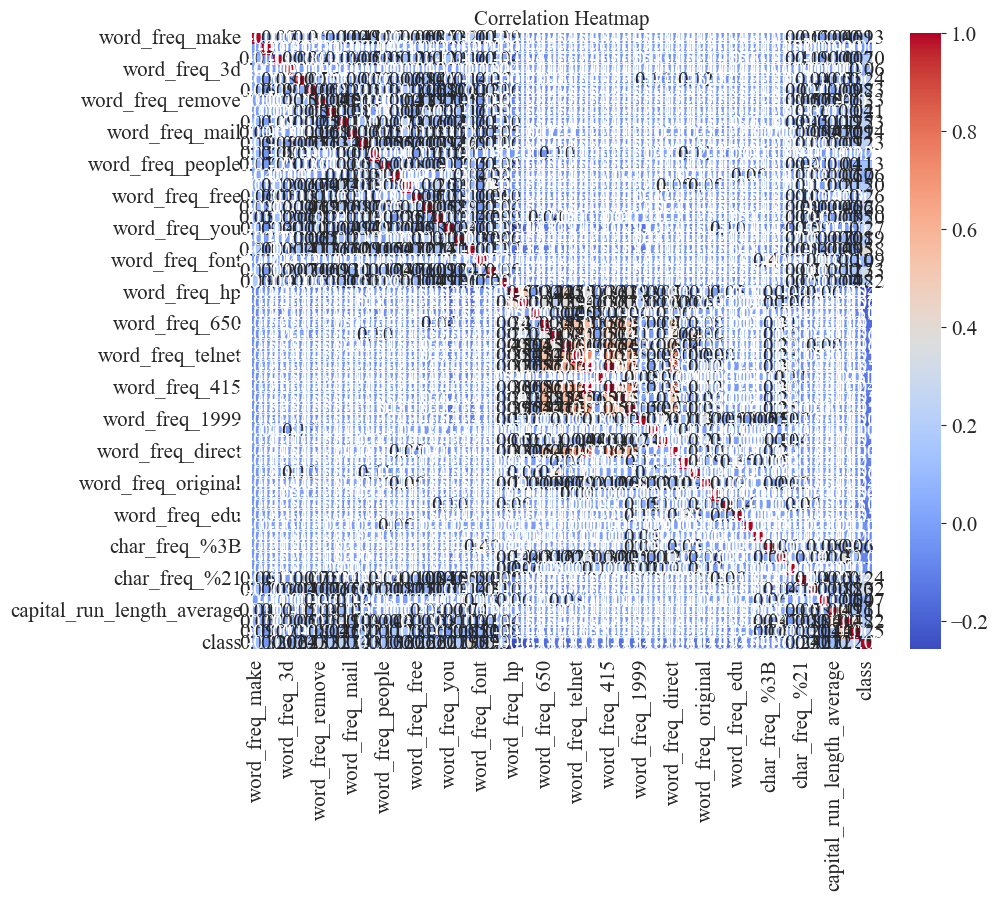


Highly Correlated Feature Pairs
word_freq_857, word_freq_415 = 0.9960660509313944
word_freq_857, word_freq_direct = 0.848020708618814
word_freq_415, word_freq_direct = 0.8453591164400025


TARGET ANALYSIS
class
0    2788
1    1813
Name: count, dtype: int64


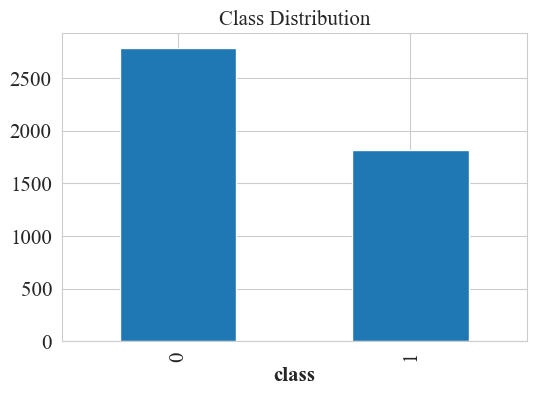



FINAL EDA SUMMARY
Rows                     : 4601
Columns                  : 58
Numerical Columns        : 58
Categorical Columns      : 0
Duplicate Rows           : 391
Columns with Missing     : 0
Highly Correlated Pairs  : 3

EDA Completed Successfully.


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


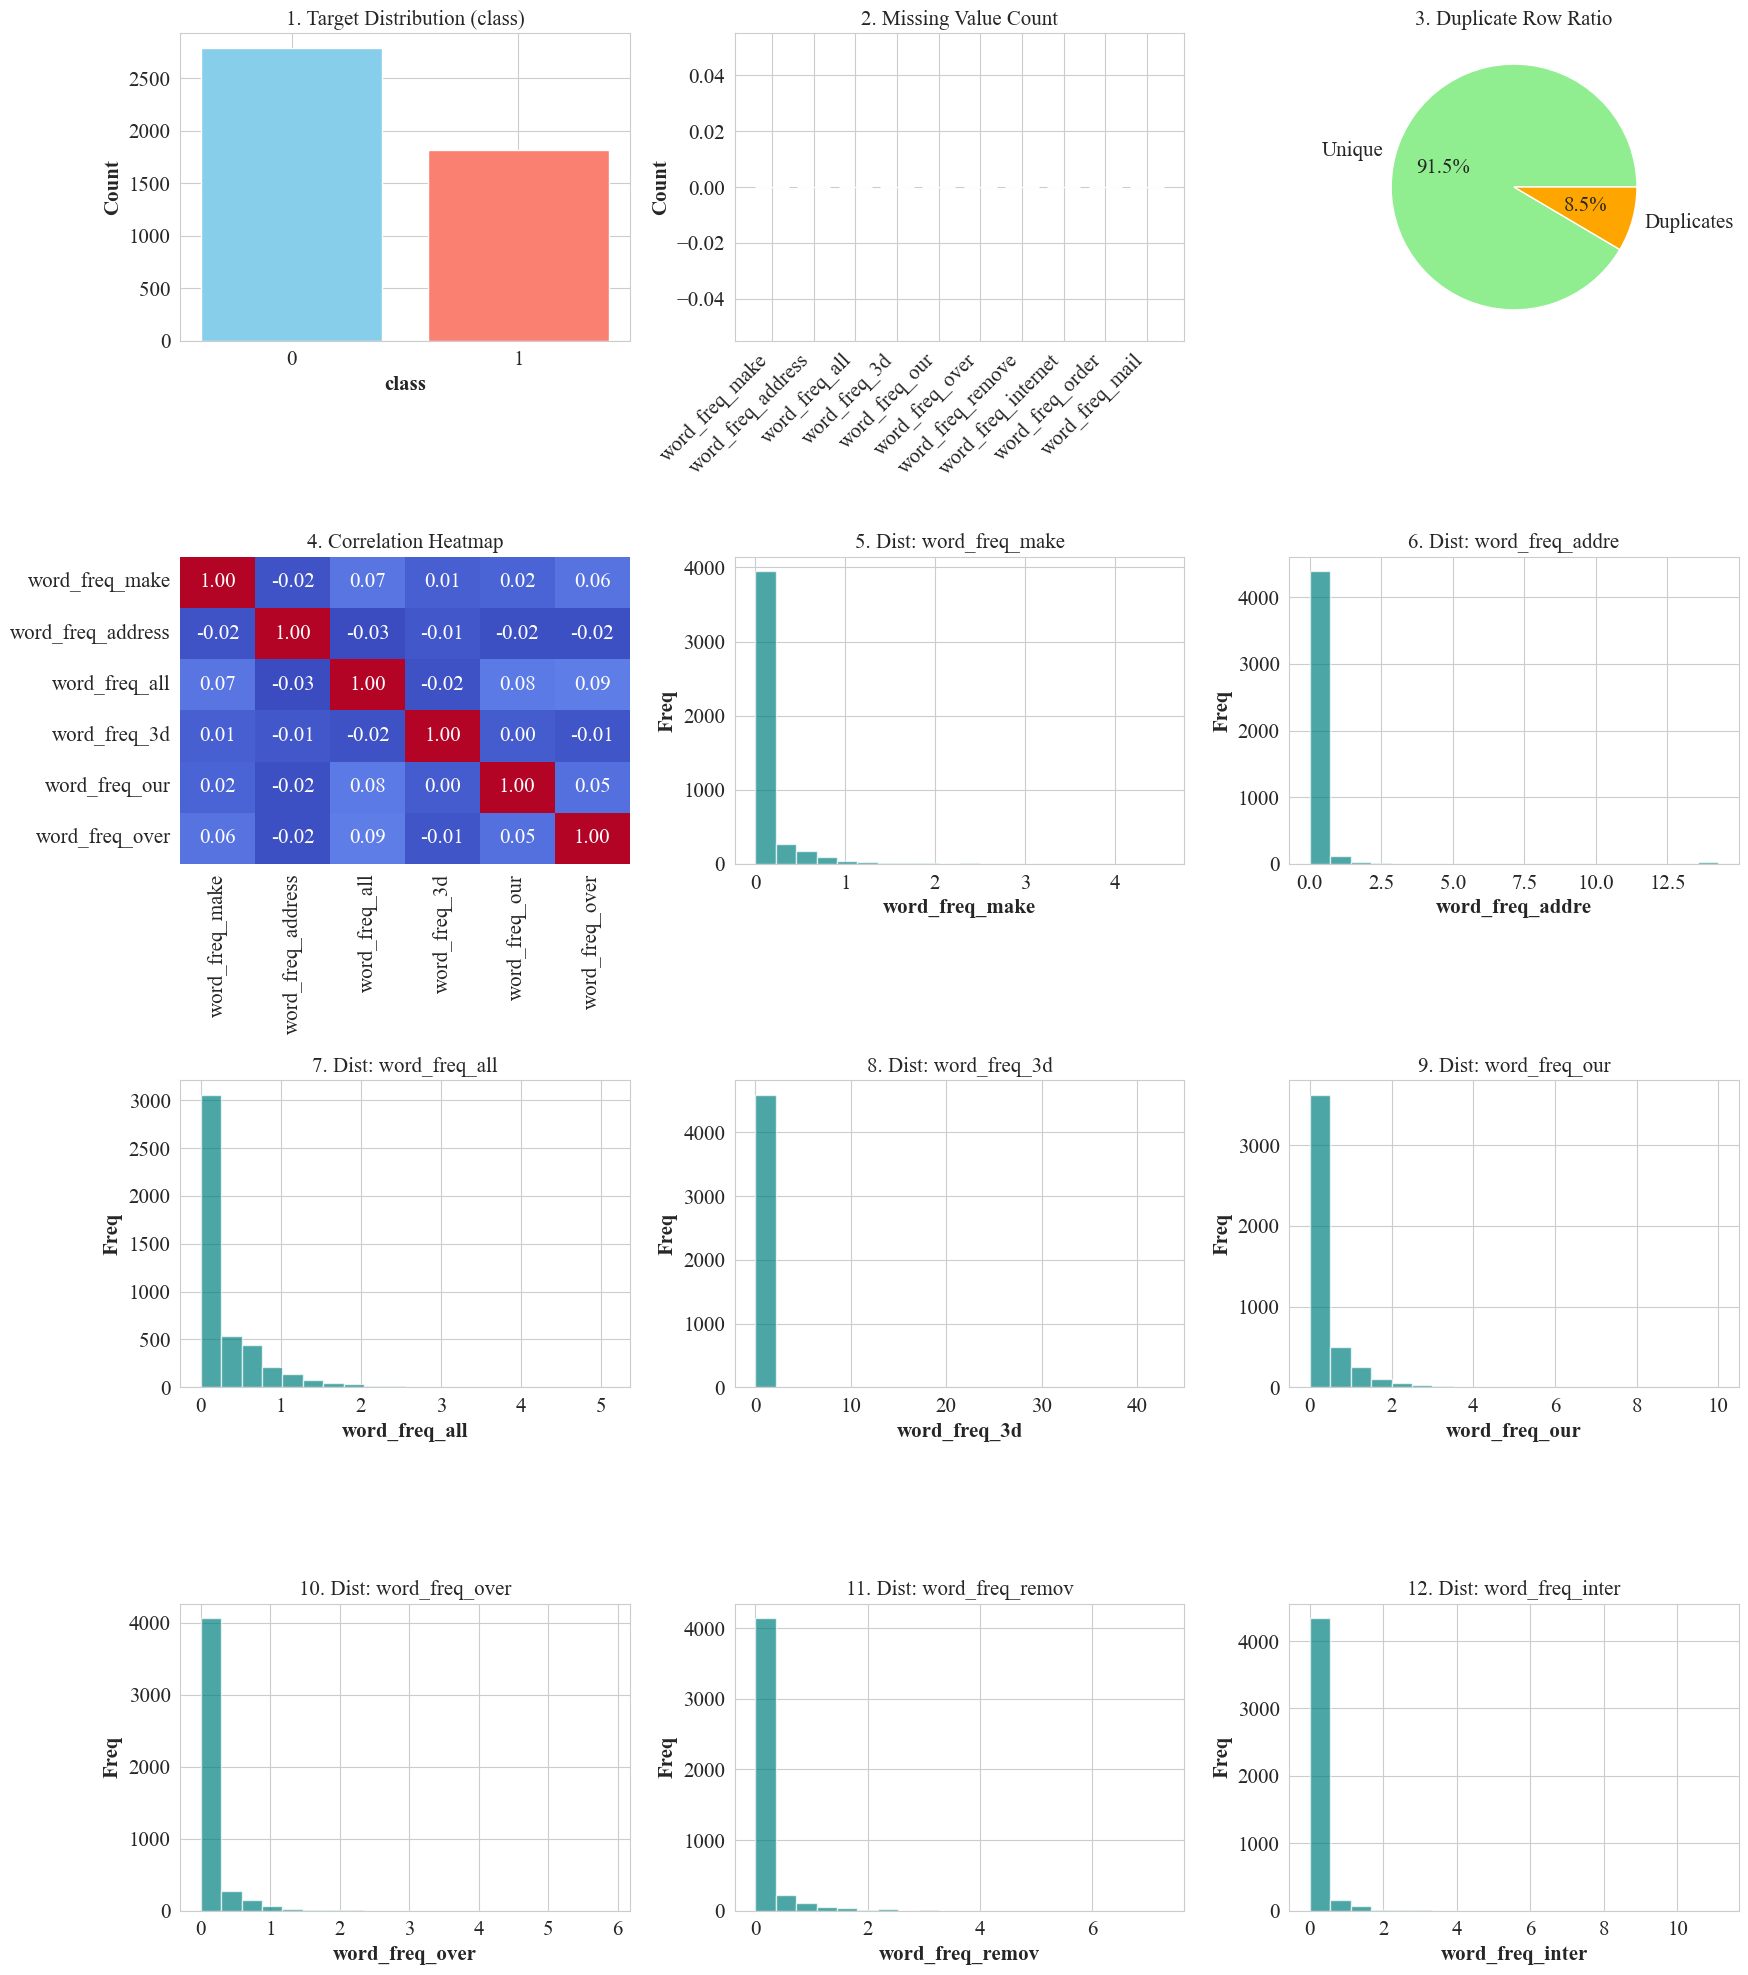

Consolidated EDA 12-subplot figure saved as 'exp2_eda_12_subplots.eps' at 600 DPI.


In [5]:
tabular_eda(df, "classification", "class")

(Skipping the process of handling the missing values, since there are no missing values in the dataset)

### Remove Duplicate Rows
The EDA duplicate-analysis step above reports duplicate rows in the dataset. Duplicate emails are removed so the same record does not appear in both the train and test split.

In [6]:
print("Shape before de-duplication:", df.shape)
df = df.drop_duplicates()
print("Duplicate rows remaining:", df.duplicated().sum())
print("Shape after de-duplication:", df.shape)

Shape before de-duplication: (4601, 58)
Duplicate rows remaining: 0
Shape after de-duplication: (4210, 58)


## Step 4 — Normalize Features
Feature scaling is algorithm-dependent for this experiment:
- **Naïve Bayes variants** are trained on features in their natural scale/representation — Gaussian NB uses the raw continuous frequencies, Multinomial NB requires non-negative counts/frequencies (already satisfied by the word/char-frequency features), and Bernoulli NB requires binary features (handled by thresholding in Step 6).
- **KNN** is distance-based, so it is sensitive to feature scale. Its features are standardized with `StandardScaler` (zero mean, unit variance) right before KNN training in Step 6.

This is why scaling is applied locally, next to the model that needs it, rather than globally to the whole dataset up front.

In [7]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

## Step 5 — Split Data into Train and Test Sets
Separate the features (`X`) from the target (`y`), and splitting them using train_test_split of sklearn library.

In [8]:
X = df.drop("class", axis=1)
y = df["class"]

print("Features shape:", X.shape)
print("Target distribution:\n", y.value_counts(normalize=True))

Features shape: (4210, 57)
Target distribution:
 class
0    0.601188
1    0.398812
Name: proportion, dtype: float64


In [9]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train shape:", X_train.shape, " Test shape:", X_test.shape)

Train shape: (3368, 57)  Test shape: (842, 57)


## Step 6 — Train Classifiers
Train four classifiers: **Gaussian NB**, **Multinomial NB**, **Bernoulli NB**, and a baseline **KNN**. Each variant of Naïve Bayes needs a different feature representation, and KNN needs standardized features. Training and prediction time are timed for every model — these timings is used in the **Experimental Time Analysis** table and plots.

### Metric imports and a reusable evaluation function
`evaluate_model` helper function prints Accuracy/Precision/Recall/F1/ROC-AUC, a full classification report, the confusion matrix, and the ROC curve for any fitted model.

In [10]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

In [11]:
# Reusable classification performance metrics display function (rules.md Section 4.5)
def display_classification_metrics(y_true, y_pred, y_prob=None, model_name="Model"):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average='weighted', zero_division=0)
    rec = recall_score(y_true, y_pred, average='weighted', zero_division=0)
    f1 = f1_score(y_true, y_pred, average='weighted', zero_division=0)
    
    print("=" * 60)
    print(f"Classification Metrics — {model_name}")
    print("=" * 60)
    print(f"Accuracy  : {acc:.4f}")
    print(f"Precision : {prec:.4f}")
    print(f"Recall    : {rec:.4f}")
    print(f"F1 Score  : {f1:.4f}")
    if y_prob is not None:
        try:
            auc = roc_auc_score(y_true, y_prob)
            print(f"ROC AUC   : {auc:.4f}")
        except Exception:
            pass
    return {'Accuracy': acc, 'Precision': prec, 'Recall': rec, 'F1': f1}

# Reusable classification training and evaluation function (rules.md Section 4.3)
def train_and_evaluate_classification(model, X_train, y_train, X_test, y_test, model_name="Model"):
    start = time.perf_counter()
    model.fit(X_train, y_train)
    train_time = time.perf_counter() - start
    
    start = time.perf_counter()
    y_pred = model.predict(X_test)
    pred_time = time.perf_counter() - start
    
    y_prob = None
    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_test)[:, 1]
        
    metrics = display_classification_metrics(y_test, y_pred, y_prob, model_name)
    metrics['Train Time (s)'] = train_time
    metrics['Pred Time (s)'] = pred_time
    
    # Confusion matrix plot formatted as per rules.md
    cm = confusion_matrix(y_test, y_pred)
    fig, ax = plt.subplots(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax)
    ax.set_title(f'Confusion Matrix — {model_name}')
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('True Label')
    plt.tight_layout()
    plt.savefig(f'exp2_cm_{model_name.replace(" ", "_")}.eps', format='eps', dpi=600, bbox_inches='tight')
    plt.show()
    
    return metrics

# Backwards compatibility alias for existing calls
def evaluate_model(model, X_test, y_test):
    model_name = type(model).__name__
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1] if hasattr(model, 'predict_proba') else None
    display_classification_metrics(y_test, y_pred, y_prob, model_name)


### 6a. Gaussian Naïve Bayes
Uses the raw (continuous) feature values — Gaussian NB models each feature as normally distributed within each class.

In [12]:
X_train_nb = X_train
X_test_nb = X_test

from sklearn.naive_bayes import GaussianNB

gnb = GaussianNB()

start = time.perf_counter()
gnb.fit(X_train_nb, y_train)
gnb_train_time = time.perf_counter() - start

start = time.perf_counter()
pred_g = gnb.predict(X_test_nb)
gnb_predict_time = time.perf_counter() - start

print("Train Time:", gnb_train_time)
print("Prediction Time:", gnb_predict_time)

Train Time: 0.01338500005658716
Prediction Time: 0.007243199972435832


### 6b. Multinomial Naïve Bayes
Uses the raw non-negative frequency features directly (Multinomial NB expects count-like/frequency features).

In [13]:
X_train_multi = X_train
X_test_multi = X_test

from sklearn.naive_bayes import MultinomialNB

mnb = MultinomialNB()

start = time.perf_counter()
mnb.fit(X_train_multi, y_train)
mnb_train_time = time.perf_counter() - start

start = time.perf_counter()
pred_m = mnb.predict(X_test_multi)
mnb_predict_time = time.perf_counter() - start

print("Train Time:", mnb_train_time)
print("Prediction Time:", mnb_predict_time)

Train Time: 0.015342599945142865
Prediction Time: 0.004521599970757961


### 6c. Bernoulli Naïve Bayes
Features are binarized (`value > 0`) since Bernoulli NB expects binary (presence/absence) features.

In [14]:
X_train_ber = (X_train > 0).astype(int)
X_test_ber = (X_test > 0).astype(int)

from sklearn.naive_bayes import BernoulliNB

bnb = BernoulliNB()

start = time.perf_counter()
bnb.fit(X_train_ber, y_train)
bnb_train_time = time.perf_counter() - start

start = time.perf_counter()
pred_b = bnb.predict(X_test_ber)
bnb_predict_time = time.perf_counter() - start

print("Train Time:", bnb_train_time)
print("Prediction Time:", bnb_predict_time)

Train Time: 0.016210800036787987
Prediction Time: 0.0052405999740585685


### 6d. Baseline KNN
Features are standardized first (fit on train, applied to test — no leakage). A default `k=5` is used here as a baseline **before** tuning; the effect of varying `k` and the tuned value is found later steps.


In [15]:
k = 5  # baseline value before tuning

X_train_knn = scaler.fit_transform(X_train)
X_test_knn = scaler.transform(X_test)

from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=k)

start = time.perf_counter()
knn.fit(X_train_knn, y_train)
knn_train_time = time.perf_counter() - start

start = time.perf_counter()
knn.predict(X_test_knn)
knn_predict_time = time.perf_counter() - start

print("Train Time:", knn_train_time)
print("Prediction Time:", knn_predict_time)

Train Time: 0.004493399988859892
Prediction Time: 0.4821834999602288


  File "C:\Users\Balakumaran\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.11_3.11.2544.0_x64__qbz5n2kfra8p0\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.11_3.11.2544.0_x64__qbz5n2kfra8p0\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.11_3.11.2544.0_x64__qbz5n2kfra8p0\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^

### 6e. Evaluate All Four Baseline Models
Confusion matrix + ROC curve + full metric printout for each model using the helper function built.

In [16]:
evaluate_model(gnb, X_test_nb, y_test)
evaluate_model(mnb, X_test_multi, y_test)
evaluate_model(bnb, X_test_ber, y_test)
evaluate_model(knn, X_test_knn, y_test)

Classification Metrics — GaussianNB
Accuracy  : 0.8361
Precision : 0.8658
Recall    : 0.8361
F1 Score  : 0.8377
ROC AUC   : 0.9525
Classification Metrics — MultinomialNB
Accuracy  : 0.7886
Precision : 0.7869
Recall    : 0.7886
F1 Score  : 0.7864
ROC AUC   : 0.8342
Classification Metrics — BernoulliNB
Accuracy  : 0.8943
Precision : 0.8940
Recall    : 0.8943
F1 Score  : 0.8940
ROC AUC   : 0.9609


Classification Metrics — KNeighborsClassifier
Accuracy  : 0.9133
Precision : 0.9134
Recall    : 0.9133
F1 Score  : 0.9128
ROC AUC   : 0.9546


### Table — Naïve Bayes Comparison
Built directly from the metrics computed above.

In [17]:
nb_comparison = pd.DataFrame({
    "Gaussian": [
        accuracy_score(y_test, pred_g),
        precision_score(y_test, pred_g),
        recall_score(y_test, pred_g),
        f1_score(y_test, pred_g),
        roc_auc_score(y_test, gnb.predict_proba(X_test_nb)[:, 1]),
    ],
    "Multinomial": [
        accuracy_score(y_test, pred_m),
        precision_score(y_test, pred_m),
        recall_score(y_test, pred_m),
        f1_score(y_test, pred_m),
        roc_auc_score(y_test, mnb.predict_proba(X_test_multi)[:, 1]),
    ],
    "Bernoulli": [
        accuracy_score(y_test, pred_b),
        precision_score(y_test, pred_b),
        recall_score(y_test, pred_b),
        f1_score(y_test, pred_b),
        roc_auc_score(y_test, bnb.predict_proba(X_test_ber)[:, 1]),
    ],
}, index=["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"])

nb_comparison

,Gaussian,Multinomial,Bernoulli
Accuracy,0.836105,0.788599,0.894299
Precision,0.723982,0.761589,0.877676
Recall,0.952381,0.684524,0.854167
F1,0.822622,0.721003,0.865762
ROC-AUC,0.952472,0.834245,0.960863


## Step 7 — Study the Effect of Varying k
Sweep `k` over a wide range and plot accuracy vs. `k` , then using it to build the **Required KNN Comparison Table** at the specific values k = 1, 3, 5, 7, 9, 11, 15 mentioned in the experiment.


In [18]:
k_values = [1, 3, 5, 7, 9, 11, 13, 15]

### Accuracy vs. k


[0.9049881235154394, 0.9097387173396675, 0.9133016627078385, 0.9049881235154394, 0.9073634204275535, 0.9085510688836105, 0.9049881235154394, 0.9049881235154394] 




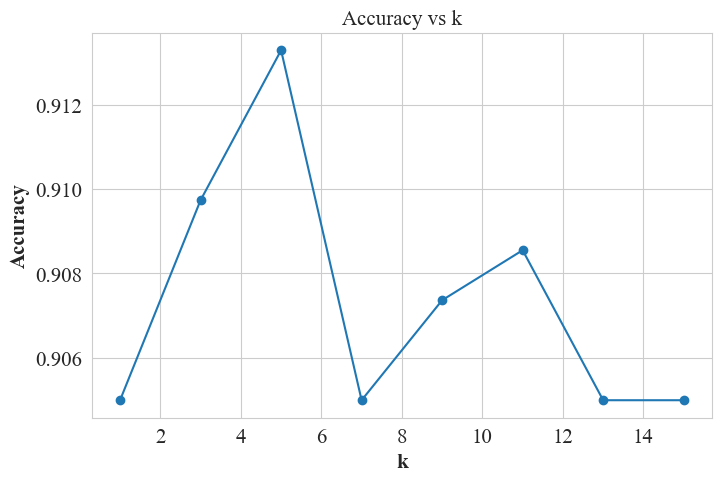

In [19]:
scores = []

for kk in range(1, 16, 2):
    knn_k = KNeighborsClassifier(n_neighbors=kk)
    knn_k.fit(X_train_knn, y_train)
    pred = knn_k.predict(X_test_knn)
    scores.append(accuracy_score(y_test, pred))

print(scores, "\n\n")
plt.figure(figsize=(8, 5))
plt.plot(range(1, 16, 2), scores, marker='o')
plt.xlabel("k")
plt.ylabel("Accuracy")
plt.title("Accuracy vs k")
plt.show()

### Table — KNN Comparison (k = 1, 3, 5, 7, 9, 11)

In [20]:
knn_table_rows = []
for kk in [1, 3, 5, 7, 9, 11]:
    knn_k = KNeighborsClassifier(n_neighbors=kk)
    knn_k.fit(X_train_knn, y_train)
    pred = knn_k.predict(X_test_knn)
    knn_table_rows.append({
        "k": kk,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
    })

knn_comparison_table = pd.DataFrame(knn_table_rows).set_index("k")
knn_comparison_table

,Accuracy,Precision,Recall,F1
k,,,,
1,0.904988,0.883234,0.877976,0.880597
3,0.909739,0.906250,0.863095,0.884146
5,0.913302,0.914826,0.863095,0.888208
7,0.904988,0.910256,0.845238,0.876543
9,0.907363,0.924342,0.836310,0.878125
11,0.908551,0.916399,0.848214,0.880989


## Step 8 — Tune KNN using GridSearchCV
Exhaustively search over `n_neighbors`, `weights`, `metric` (Euclidean/Manhattan — covers the **Additional Task** "Compare Euclidean and Manhattan distances" as part of the grid), `algorithm` (KDTree/BallTree) and `leaf_size`, optimizing F1-score with 5-fold CV.

In [21]:
param_grid = {
    'n_neighbors': [1, 3, 5, 7, 9, 11, 13, 15],
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan'],
    'algorithm': ['kd_tree', 'ball_tree'],
    'leaf_size': [20, 30, 40]
}

from sklearn.model_selection import GridSearchCV

grid_knn = GridSearchCV(
    estimator=KNeighborsClassifier(),
    param_grid=param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1
)

start = time.perf_counter()
grid_knn.fit(X_train_knn, y_train)
grid_train_time = time.perf_counter() - start

print("Best Parameters:", grid_knn.best_params_)
print("Best CV Score:", grid_knn.best_score_)

start = time.perf_counter()
grid_knn.predict(X_test_knn)
grid_predict_time = time.perf_counter() - start

print("Train Time:", grid_train_time)
print("Prediction Time:", grid_predict_time)

Best Parameters: {'algorithm': 'kd_tree', 'leaf_size': 20, 'metric': 'manhattan', 'n_neighbors': 9, 'weights': 'distance'}
Best CV Score: 0.8863910764621735


Train Time: 150.50450999999885
Prediction Time: 0.7759724999777973


### Evaluate the Best GridSearchCV Model

Accuracy : 0.9275534441805225
Precision: 0.959866220735786
Recall   : 0.8541666666666666
F1 Score : 0.9039370078740158
ROC AUC  : 0.9746170948616601

Classification Report

              precision    recall  f1-score   support

           0       0.91      0.98      0.94       506
           1       0.96      0.85      0.90       336

    accuracy                           0.93       842
   macro avg       0.93      0.92      0.92       842
weighted avg       0.93      0.93      0.93       842



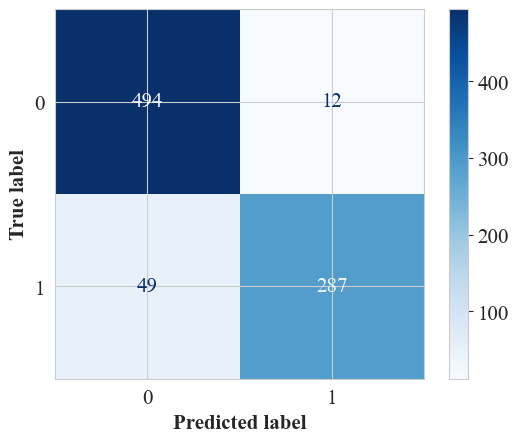

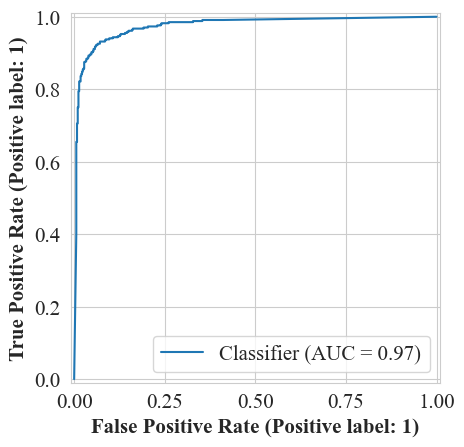

In [22]:
best_knn_grid = grid_knn.best_estimator_

y_pred = best_knn_grid.predict(X_test_knn)
y_prob = best_knn_grid.predict_proba(X_test_knn)[:, 1]

print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall   :", recall_score(y_test, y_pred))
print("F1 Score :", f1_score(y_test, y_pred))
print("ROC AUC  :", roc_auc_score(y_test, y_prob))

print("\nClassification Report\n")
print(classification_report(y_test, y_pred))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues")
plt.show()

RocCurveDisplay.from_predictions(y_test, y_prob)
plt.show()

### Plot — GridSearchCV Heatmap (mean F1 vs n_neighbors & weights)

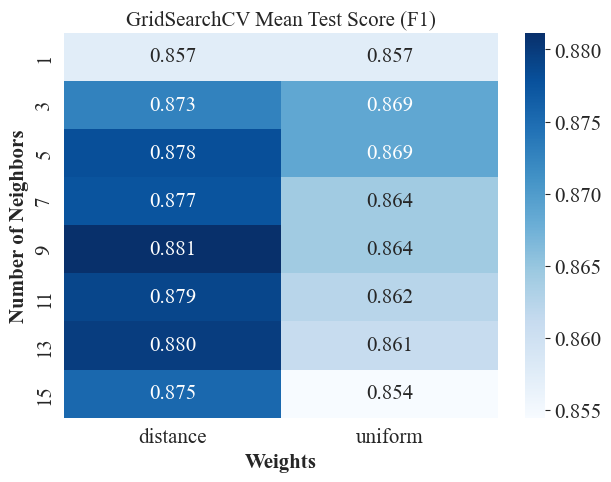

In [23]:
cv_results_grid = pd.DataFrame(grid_knn.cv_results_)

heatmap_data = (
    cv_results_grid
    .groupby(["param_n_neighbors", "param_weights"])["mean_test_score"]
    .mean()
    .unstack()
)

plt.figure(figsize=(7, 5))
sns.heatmap(heatmap_data, annot=True, fmt=".3f", cmap="Blues")
plt.title("GridSearchCV Mean Test Score (F1)")
plt.xlabel("Weights")
plt.ylabel("Number of Neighbors")
plt.show()

## Step 9 — Tune KNN using RandomizedSearchCV
Randomly sample 30 parameter combinations from the same grid, again optimizing F1 with 5-fold CV — much cheaper than the exhaustive grid search, at the cost of not guaranteeing the global optimum.


In [24]:
from sklearn.model_selection import RandomizedSearchCV

random_knn = RandomizedSearchCV(
    estimator=KNeighborsClassifier(),
    param_distributions=param_grid,
    n_iter=30,
    cv=5,
    scoring='f1',
    random_state=42,
    n_jobs=-1
)

start = time.perf_counter()
random_knn.fit(X_train_knn, y_train)
random_train_time = time.perf_counter() - start

print("Best Parameters:", random_knn.best_params_)
print("Best CV Score:", random_knn.best_score_)

start = time.perf_counter()
random_knn.predict(X_test_knn)
random_predict_time = time.perf_counter() - start

print("Train Time:", random_train_time)
print("Prediction Time:", random_predict_time)

Best Parameters: {'weights': 'distance', 'n_neighbors': 9, 'metric': 'manhattan', 'leaf_size': 30, 'algorithm': 'ball_tree'}
Best CV Score: 0.8860395934031965


Train Time: 23.237583599984646
Prediction Time: 0.5633933000499383


### Evaluate the Best RandomizedSearchCV Model
> **Fix applied:** the original notebook re-evaluated `grid_knn.best_estimator_` again here (an exact duplicate of the GridSearchCV evaluation cell) instead of evaluating the RandomizedSearchCV result. Corrected to evaluate `random_knn.best_estimator_`.

Accuracy : 0.9275534441805225
Precision: 0.959866220735786
Recall   : 0.8541666666666666
F1 Score : 0.9039370078740158
ROC AUC  : 0.9746170948616601

Classification Report

              precision    recall  f1-score   support

           0       0.91      0.98      0.94       506
           1       0.96      0.85      0.90       336

    accuracy                           0.93       842
   macro avg       0.93      0.92      0.92       842
weighted avg       0.93      0.93      0.93       842



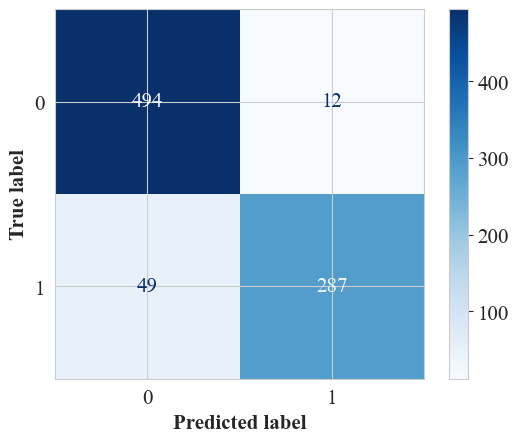

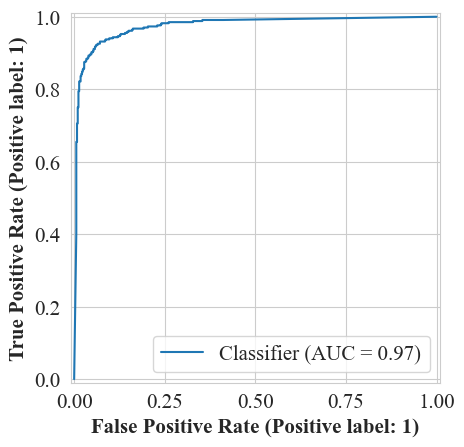

In [25]:
best_knn_random = random_knn.best_estimator_

y_pred_r = best_knn_random.predict(X_test_knn)
y_prob_r = best_knn_random.predict_proba(X_test_knn)[:, 1]

print("Accuracy :", accuracy_score(y_test, y_pred_r))
print("Precision:", precision_score(y_test, y_pred_r))
print("Recall   :", recall_score(y_test, y_pred_r))
print("F1 Score :", f1_score(y_test, y_pred_r))
print("ROC AUC  :", roc_auc_score(y_test, y_prob_r))

print("\nClassification Report\n")
print(classification_report(y_test, y_pred_r))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_r, cmap="Blues")
plt.show()

RocCurveDisplay.from_predictions(y_test, y_prob_r)
plt.show()

### Plot — RandomizedSearchCV Score Distribution

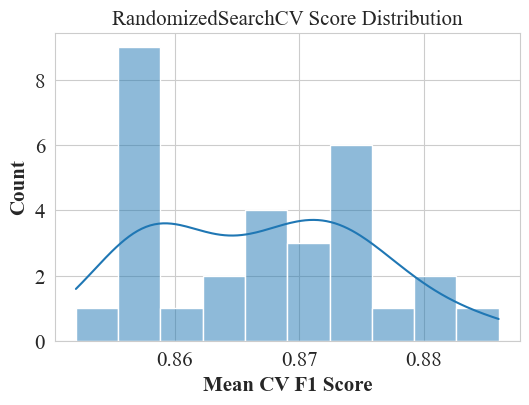

In [26]:
scores_rand = random_knn.cv_results_["mean_test_score"]

plt.figure(figsize=(6, 4))
sns.histplot(scores_rand, bins=10, kde=True)
plt.xlabel("Mean CV F1 Score")
plt.title("RandomizedSearchCV Score Distribution")
plt.show()

###Table — GridSearchCV vs RandomizedSearchCV


In [27]:
search_comparison = pd.DataFrame({
    "GridSearchCV": [
        grid_knn.best_params_['n_neighbors'],
        grid_knn.best_params_['metric'],
        grid_knn.best_params_['weights'],
        grid_knn.best_params_['algorithm'],
        grid_knn.best_score_,
        grid_train_time,
    ],
    "RandomizedSearchCV": [
        random_knn.best_params_['n_neighbors'],
        random_knn.best_params_['metric'],
        random_knn.best_params_['weights'],
        random_knn.best_params_['algorithm'],
        random_knn.best_score_,
        random_train_time,
    ],
}, index=["Best k", "Metric", "Weights", "Algorithm", "CV F1 Score", "Execution Time (s)"])

search_comparison

,GridSearchCV,RandomizedSearchCV
Best k,9,9
Metric,manhattan,manhattan
Weights,distance,distance
Algorithm,kd_tree,ball_tree
CV F1 Score,0.886391,0.88604
Execution Time (s),150.50451,23.237584


## Step 10 — Compare KDTree and BallTree
The original notebook swept accuracy across `k_values` for `algorithm="kd_tree"` and `algorithm="ball_tree"` separately (two nearly-identical plots).

### Accuracy vs k — KDTree

[0.9049881235154394, 0.9097387173396675, 0.9133016627078385, 0.9049881235154394, 0.9073634204275535, 0.9085510688836105, 0.9049881235154394, 0.9049881235154394] 




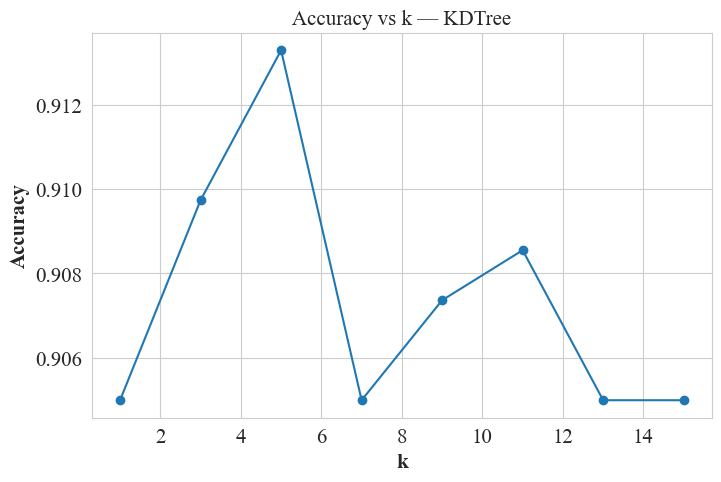

In [28]:
scores = []
for k in k_values:
    knn_kd = KNeighborsClassifier(n_neighbors=k, algorithm="kd_tree")
    knn_kd.fit(X_train_knn, y_train)
    pred = knn_kd.predict(X_test_knn)
    scores.append(accuracy_score(y_test, pred))

print(scores, "\n\n")
plt.figure(figsize=(8, 5))
plt.plot(k_values, scores, marker='o')
plt.xlabel("k")
plt.ylabel("Accuracy")
plt.title("Accuracy vs k — KDTree")
plt.show()

### Accuracy vs k — BallTree

[0.9049881235154394, 0.9097387173396675, 0.9133016627078385, 0.9049881235154394, 0.9073634204275535, 0.9085510688836105, 0.9049881235154394, 0.9049881235154394] 




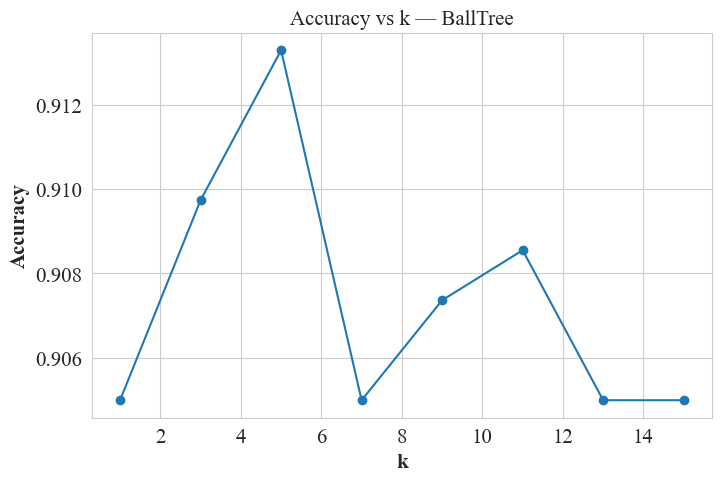

In [29]:
scores = []
for kk in k_values:
    knn_bt = KNeighborsClassifier(n_neighbors=kk, algorithm="ball_tree")
    knn_bt.fit(X_train_knn, y_train)
    pred = knn_bt.predict(X_test_knn)
    scores.append(accuracy_score(y_test, pred))

print(scores, "\n\n")
plt.figure(figsize=(8, 5))
plt.plot(k_values, scores, marker='o')
plt.xlabel("k")
plt.ylabel("Accuracy")
plt.title("Accuracy vs k — BallTree")
plt.show()

### Table — KDTree vs BallTree (Accuracy, Training Time, Prediction Time)


In [30]:
best_k_tuned = grid_knn.best_params_['n_neighbors']

# KDTree
knn_kd = KNeighborsClassifier(n_neighbors=best_k_tuned, algorithm="kd_tree")
start = time.perf_counter()
knn_kd.fit(X_train_knn, y_train)
kd_train_time = time.perf_counter() - start

start = time.perf_counter()
pred_kd = knn_kd.predict(X_test_knn)
kd_predict_time = time.perf_counter() - start

# BallTree
knn_bt = KNeighborsClassifier(n_neighbors=best_k_tuned, algorithm="ball_tree")
start = time.perf_counter()
knn_bt.fit(X_train_knn, y_train)
ball_train_time = time.perf_counter() - start

start = time.perf_counter()
pred_bt = knn_bt.predict(X_test_knn)
ball_predict_time = time.perf_counter() - start

tree_comparison = pd.DataFrame({
    "KDTree": [accuracy_score(y_test, pred_kd), kd_train_time, kd_predict_time],
    "BallTree": [accuracy_score(y_test, pred_bt), ball_train_time, ball_predict_time],
}, index=["Accuracy", "Training Time (s)", "Prediction Time (s)"])

tree_comparison

,KDTree,BallTree
Accuracy,0.907363,0.907363
Training Time (s),0.058915,0.037032
Prediction Time (s),0.468512,0.431749


## Step 11 — K-Fold Cross Validation
5-fold cross validation is run for the best-performing Naïve Bayes variant (selected from the **NB Comparison Table** in Step 6) and the tuned KNN, matching the "Fold | Naïve Bayes Best | KNN" table required by the experiment sheet.

In [31]:
best_nb_name = nb_comparison.loc["F1"].idxmax()
print("Best Naive Bayes variant (by F1):", best_nb_name)

best_nb_model = {"Gaussian": gnb, "Multinomial": mnb, "Bernoulli": bnb}[best_nb_name]
best_nb_X = {"Gaussian": X, "Multinomial": X, "Bernoulli": (X > 0).astype(int)}[best_nb_name]

Best Naive Bayes variant (by F1): Bernoulli


In [32]:
from sklearn.model_selection import cross_val_score

X_scaled = scaler.fit_transform(X)

knn_cv_scores = cross_val_score(best_knn_grid, X_scaled, y, cv=5, scoring='accuracy')
nb_cv_scores = cross_val_score(best_nb_model, best_nb_X, y, cv=5, scoring='accuracy')

# Comparison Table
cv_results = pd.DataFrame({
    "Model": [f"Best Naive Bayes ({best_nb_name})", "Best KNN"],
    "Mean Accuracy": [nb_cv_scores.mean(), knn_cv_scores.mean()],
    "Standard Deviation": [nb_cv_scores.std(), knn_cv_scores.std()],
})

print("5-Fold Cross Validation Results")
print(cv_results)

print(f"\nBest Naive Bayes ({best_nb_name}) Fold Accuracies:")
print(nb_cv_scores)

print("\nBest KNN Fold Accuracies:")
print(knn_cv_scores)

5-Fold Cross Validation Results
                          Model  Mean Accuracy  Standard Deviation
0  Best Naive Bayes (Bernoulli)       0.882660            0.051923
1                      Best KNN       0.895249            0.030892

Best Naive Bayes (Bernoulli) Fold Accuracies:
[0.90973872 0.90261283 0.90736342 0.91448931 0.77909739]

Best KNN Fold Accuracies:
[0.87292162 0.90736342 0.92992874 0.9192399  0.84679335]


### Table — Cross Validation (Fold-wise)

In [33]:
fold_table = pd.DataFrame({
    "Fold": [1, 2, 3, 4, 5],
    f"Naive Bayes Best ({best_nb_name})": nb_cv_scores,
    "KNN": knn_cv_scores,
})
avg_row = pd.DataFrame({
    "Fold": ["Average"],
    f"Naive Bayes Best ({best_nb_name})": [nb_cv_scores.mean()],
    "KNN": [knn_cv_scores.mean()],
})
fold_table = pd.concat([fold_table, avg_row], ignore_index=True)
fold_table

,Fold,Naive Bayes Best (Bernoulli),KNN
0,1,0.909739,0.872922
1,2,0.902613,0.907363
2,3,0.907363,0.929929
3,4,0.914489,0.919240
4,5,0.779097,0.846793
5,Average,0.882660,0.895249


### Plot — 5-Fold CV Accuracy Bar Chart

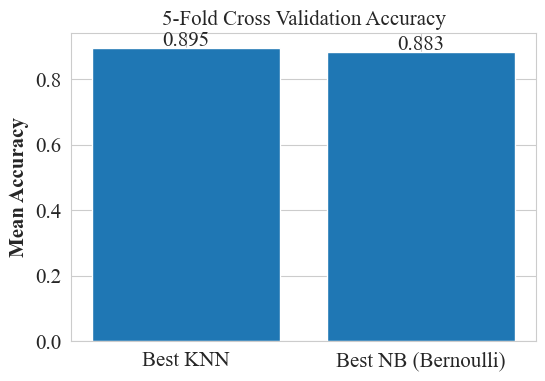

In [34]:
models_cv = ["Best KNN", f"Best NB ({best_nb_name})"]
scores_cv = [knn_cv_scores.mean(), nb_cv_scores.mean()]

plt.figure(figsize=(6, 4))
plt.bar(models_cv, scores_cv)
plt.ylabel("Mean Accuracy")
plt.title("5-Fold Cross Validation Accuracy")

for i, v in enumerate(scores_cv):
    plt.text(i, v + 0.005, f"{v:.3f}", ha='center')

plt.show()

## Step 12 — Computational Complexity and Execution Time
First the **theoretical** time complexity (from the experiment sheet, n = number of samples, d = number of features), then the **experimental** measured training/prediction times collected throughout the notebook, and finally the remaining required plots.

### Table — Theoretical Time Complexity

| Algorithm | Training | Prediction |
|---|---|---|
| Naïve Bayes | O(nd) | O(d) |
| KNN (Brute) | O(1) | O(nd) |
| KDTree | O(n log n) | O(log n) avg |
| BallTree | O(n log n) | O(log n) avg |


### Table — Experimental Time Analysis

In [35]:
experimental_time = pd.DataFrame({
    "Training(s)": [gnb_train_time, mnb_train_time, bnb_train_time, knn_train_time],
    "Prediction(s)": [gnb_predict_time, mnb_predict_time, bnb_predict_time, knn_predict_time],
}, index=["Gaussian NB", "Multinomial NB", "Bernoulli NB", "Best KNN (baseline k)"])

experimental_time

,Training(s),Prediction(s)
Gaussian NB,0.013385,0.007243
Multinomial NB,0.015343,0.004522
Bernoulli NB,0.016211,0.005241
Best KNN (baseline k),0.004493,0.482183


### Plot — Precision-Recall Curves (all four models)

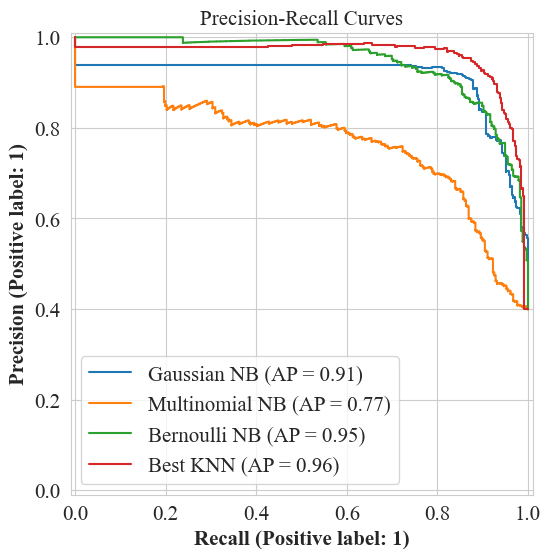

In [36]:
from sklearn.metrics import PrecisionRecallDisplay

models = {
    "Gaussian NB": gnb,
    "Multinomial NB": mnb,
    "Bernoulli NB": bnb,
    "Best KNN": best_knn_grid
}

plt.figure(figsize=(8, 6))

for name, model in models.items():
    if "KNN" in name:
        y_prob = model.predict_proba(X_test_knn)[:, 1]
    elif name == "Bernoulli NB":
        y_prob = model.predict_proba(X_test_ber)[:, 1]
    else:
        y_prob = model.predict_proba(X_test)[:, 1]
    PrecisionRecallDisplay.from_predictions(y_test, y_prob, name=name, ax=plt.gca())

plt.title("Precision-Recall Curves")
plt.grid(True)
plt.show()

### Plot — Training Time Comparison

{'Gaussian NB': 0.01338500005658716, 'Multinomial NB': 0.015342599945142865, 'Bernoulli NB': 0.016210800036787987, 'Best KNN': 0.004493399988859892, 'KDTree': 0.058915200061164796, 'BallTree': 0.037031800020486116}


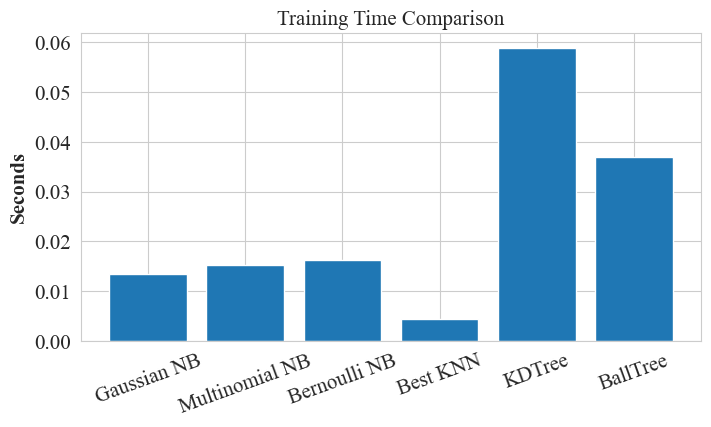

In [37]:
training_times = {
    "Gaussian NB": gnb_train_time,
    "Multinomial NB": mnb_train_time,
    "Bernoulli NB": bnb_train_time,
    "Best KNN": knn_train_time,
    "KDTree": kd_train_time,
    "BallTree": ball_train_time
}
print(training_times)

plt.figure(figsize=(8, 4))
plt.bar(training_times.keys(), training_times.values())
plt.xticks(rotation=20)
plt.ylabel("Seconds")
plt.title("Training Time Comparison")
plt.show()

### Plot — Prediction Time Comparison

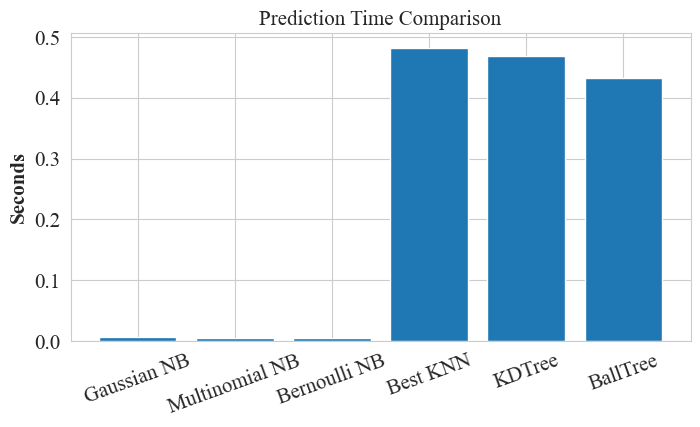

In [38]:
prediction_times = {
    "Gaussian NB": gnb_predict_time,
    "Multinomial NB": mnb_predict_time,
    "Bernoulli NB": bnb_predict_time,
    "Best KNN": knn_predict_time,
    "KDTree": kd_predict_time,
    "BallTree": ball_predict_time
}

plt.figure(figsize=(8, 4))
plt.bar(prediction_times.keys(), prediction_times.values())
plt.xticks(rotation=20)
plt.ylabel("Seconds")
plt.title("Prediction Time Comparison")
plt.show()

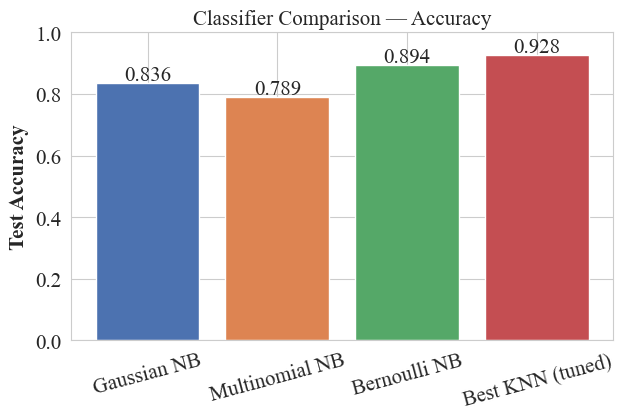

In [39]:
classifier_acc = {
    "Gaussian NB": accuracy_score(y_test, pred_g),
    "Multinomial NB": accuracy_score(y_test, pred_m),
    "Bernoulli NB": accuracy_score(y_test, pred_b),
    "Best KNN (tuned)": accuracy_score(y_test, y_pred),
}

plt.figure(figsize=(7, 4))
bars = plt.bar(classifier_acc.keys(), classifier_acc.values(), color=["#4C72B0", "#DD8452", "#55A868", "#C44E52"])
plt.ylabel("Test Accuracy")
plt.title("Classifier Comparison — Accuracy")
plt.ylim(0, 1)
for bar, v in zip(bars, classifier_acc.values()):
    plt.text(bar.get_x() + bar.get_width()/2, v + 0.01, f"{v:.3f}", ha='center')
plt.xticks(rotation=15)
plt.show()

## Additional Tasks


### 1. Evaluate Different Train-Test Splits

In [40]:
split_results = []
for test_size in [0.1, 0.2, 0.3]:
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=test_size, random_state=42, stratify=y)
    sc = StandardScaler()
    Xtr_s = sc.fit_transform(Xtr)
    Xte_s = sc.transform(Xte)

    model = KNeighborsClassifier(**{kk: vv for kk, vv in grid_knn.best_params_.items()})
    model.fit(Xtr_s, ytr)
    pred = model.predict(Xte_s)

    split_results.append({
        "Test Size": test_size,
        "Train Rows": Xtr.shape[0],
        "Test Rows": Xte.shape[0],
        "Accuracy": accuracy_score(yte, pred),
        "F1": f1_score(yte, pred),
    })

split_df = pd.DataFrame(split_results)
split_df

,Test Size,Train Rows,Test Rows,Accuracy,F1
0,0.1,3789,421,0.933492,0.911392
1,0.2,3368,842,0.927553,0.903937
2,0.3,2947,1263,0.920032,0.894241


### 2. Compare Euclidean and Manhattan Distances

In [41]:
distance_results = []
for metric in ["euclidean", "manhattan"]:
    model = KNeighborsClassifier(n_neighbors=best_k_tuned, metric=metric)
    model.fit(X_train_knn, y_train)
    pred = model.predict(X_test_knn)
    distance_results.append({
        "Metric": metric,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
    })

distance_df = pd.DataFrame(distance_results).set_index("Metric")
distance_df

,Accuracy,Precision,Recall,F1
Metric,,,,
euclidean,0.907363,0.924342,0.836310,0.878125
manhattan,0.913302,0.951890,0.824405,0.883573


### 3. Evaluate Weighted KNN (uniform vs distance)

In [42]:
weight_results = []
for weight in ["uniform", "distance"]:
    model = KNeighborsClassifier(n_neighbors=best_k_tuned, weights=weight)
    model.fit(X_train_knn, y_train)
    pred = model.predict(X_test_knn)
    weight_results.append({
        "Weighting": weight,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
    })

weight_df = pd.DataFrame(weight_results).set_index("Weighting")
weight_df

,Accuracy,Precision,Recall,F1
Weighting,,,,
uniform,0.907363,0.924342,0.836310,0.878125
distance,0.922803,0.930159,0.872024,0.900154


## Conclusion
Thus learnt to implement and compare Gaussian, Multinomial and Bernoulli Naïve Bayes classifiers against KNN (baseline, k-swept, and hyperparameter-tuned via GridSearchCV/RandomizedSearchCV) on the Spambase dataset. KDTree and BallTree were compared as KNN backends, 5-fold cross-validation was used for a robust performance estimate, and both theoretical and measured computational complexity were examined.